# 🤖 NewsBot Intelligence System
## ITAI 2373 - Individual Midterm Project

**Student:** Ashton Smith
**Date:** October, 16 2026
**Project type:** Individual Midterm Project
**GitHub Repository: https://github.com/Ashton-Smith/ITAI2373-NewsBot-Midterm

---

## 🎯 Project Overview

Welcome to your NewsBot Intelligence System! This notebook will guide you through building a comprehensive NLP system that:

- 📰 **Processes** news articles with advanced text cleaning
- 🏷️ **Classifies** articles into categories (Politics, Sports, Technology, Business, Entertainment, Health)
- 🔍 **Extracts** named entities (people, organizations, locations, dates, money)
- 😊 **Analyzes** sentiment and emotional tone
- 📊 **Generates** insights for business intelligence

### 📚 Module Integration Checklist
- [x] **Module 1:** NLP applications and real-world context
- [x] **Module 2:** Text preprocessing pipeline
- [x] **Module 3:** TF-IDF feature extraction
- [x] **Module 4:** POS tagging analysis
- [x] **Module 5:** Syntax parsing and semantic analysis
- [x] **Module 6:** Sentiment and emotion analysis
- [x] **Module 7:** Text classification system
- [x] **Module 8:** Named Entity Recognition

---

## 📦 Setup and Installation

Let's start by installing and importing all the libraries we'll need for our NewsBot system.

In [ ]:
# Install required packages (run this cell first!)
!pip install spacy scikit-learn nltk pandas matplotlib seaborn wordcloud plotly
!python -m spacy download en_core_web_sm

# Download NLTK data
import nltk
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('vader_lexicon')
nltk.download('averaged_perceptron_tagger')

print("✅ All packages installed successfully!")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 62.7 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.


✅ All packages installed successfully!


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package vader_lexicon to /root/nltk_data...
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger.zip.


In [ ]:
# Import all necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
import plotly.express as px
import plotly.graph_objects as go
from collections import Counter, defaultdict
import re
import warnings
warnings.filterwarnings('ignore')

# NLP Libraries
import spacy
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.stem import WordNetLemmatizer
from nltk.sentiment import SentimentIntensityAnalyzer
from nltk.tag import pos_tag

# Scikit-learn for machine learning
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.pipeline import Pipeline

# Load spaCy model
nlp = spacy.load('en_core_web_sm')

# Set up plotting style
plt.style.use('default')
sns.set_palette("husl")

print("📚 All libraries imported successfully!")
print(f"🔧 spaCy model loaded: {nlp.meta['name']} v{nlp.meta['version']}")

📚 All libraries imported successfully!
🔧 spaCy model loaded: core_web_sm v3.8.0


## 📊 Data Loading and Exploration

### 🎯 Module 1: Understanding Our NLP Application

Before we dive into the technical implementation, let's understand the real-world context of our NewsBot Intelligence System. This system addresses several business needs:

1. **Media Monitoring:** Automatically categorize and track news coverage
2. **Business Intelligence:** Extract key entities and sentiment trends
3. **Content Management:** Organize large volumes of news content
4. **Market Research:** Understand public sentiment about topics and entities

**💡 Discussion Question:** What other real-world applications can you think of for this type of system? Consider different industries and use cases.


Answer: I think this type of system could be useful in healthcare, law enforcement, and customer service. For example, hospitals could use it to analyze patient feedback and identify common complaints. Companies could use it to recognize patterns in customer reviews and better understand what people are satisfied or dissatisfied with. Instead of manually reviewing thousands of documents, AI could process the information and identify patterns that people might overlook.

In [ ]:

import pandas as pd
import zipfile

# Load the BBC News training articles directly from the ZIP
with zipfile.ZipFile('/content/learn-ai-bbc.zip') as z:
    df = pd.read_csv(z.open('BBC News Train.csv'))

# Match the column names required by our notebook
df = df.rename(columns={
    'ArticleId': 'article_id',
    'Text': 'content',
    'Category': 'category'
})

# Use a short article excerpt as a title substitute
# The Kaggle dataset does not provide separate titles
df['title'] = df['content'].str.split().str[:12].str.join(' ')
df['date'] = 'Not provided'
df['source'] = 'BBC News'

# Standardize category names
df['category'] = df['category'].replace({
    'sport': 'Sports',
    'tech': 'Technology'
}).str.title()

print("Dataset loaded successfully!")
print("Total articles:", len(df))
print("Categories:", df['category'].nunique())
print("Missing values:", df[['content', 'category']].isna().sum().sum())

df.head()


Dataset loaded successfully!
Total articles: 1490
Categories: 5
Missing values: 0


,article_id,content,category,title,date,source
0,1833,worldcom ex-boss launches defence lawyers defe...,Business,worldcom ex-boss launches defence lawyers defe...,Not provided,BBC News
1,154,german business confidence slides german busin...,Business,german business confidence slides german busin...,Not provided,BBC News
2,1101,bbc poll indicates economic gloom citizens in ...,Business,bbc poll indicates economic gloom citizens in ...,Not provided,BBC News
3,1976,lifestyle governs mobile choice faster bett...,Technology,lifestyle governs mobile choice faster better ...,Not provided,BBC News
4,917,enron bosses in $168m payout eighteen former e...,Business,enron bosses in $168m payout eighteen former e...,Not provided,BBC News


📊 DATASET OVERVIEW
Total articles: 1490
Unique categories: 5
Categories: ['Business', 'Technology', 'Politics', 'Sports', 'Entertainment']
Date range: Not provided to Not provided
Unique sources: 1

📈 CATEGORY DISTRIBUTION
category
Sports           346
Business         336
Politics         274
Entertainment    273
Technology       261
Name: count, dtype: int64


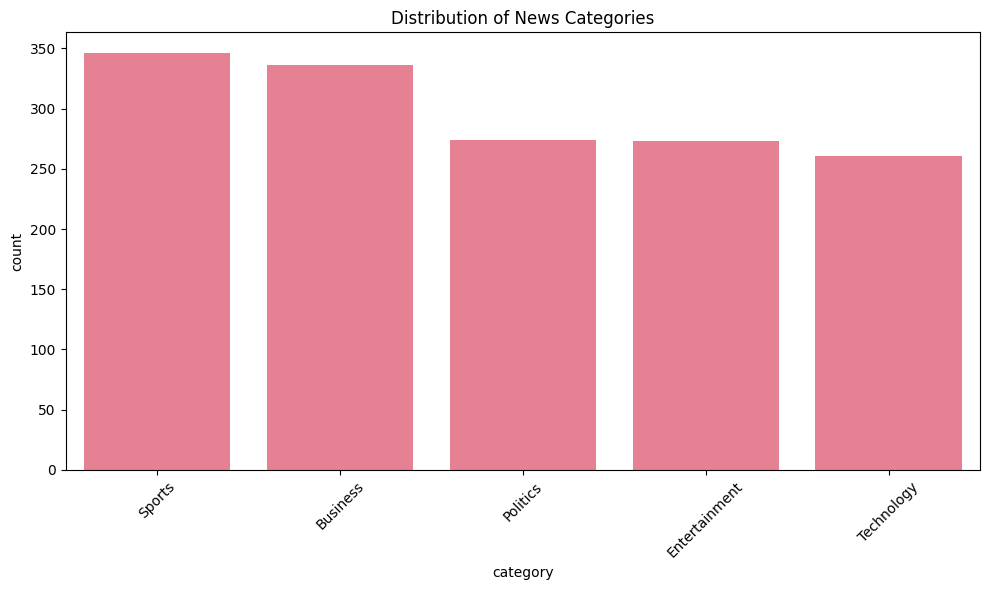

MISSING VALUES:
article_id    0
content       0
category      0
title         0
date          0
source        0
word_count    0
dtype: int64

ARTICLE LENGTH STATISTICS:
count    1490.000000
mean      385.012752
std       210.898616
min        90.000000
25%       253.000000
50%       337.000000
75%       468.750000
max      3345.000000
Name: word_count, dtype: float64


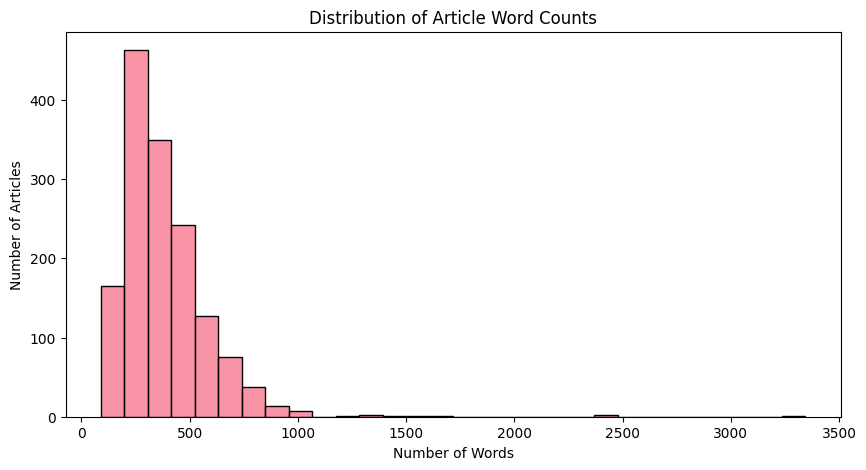


SOURCE DISTRIBUTION:
source
BBC News    1490
Name: count, dtype: int64

DATA QUALITY CHECK:
Duplicate articles: 50
Empty articles: 0
Missing category labels: 0
Articles remaining after removing duplicates: 1440
Categories remaining: 5


In [ ]:
# Basic dataset exploration
print("📊 DATASET OVERVIEW")
print("=" * 50)
print(f"Total articles: {len(df)}")
print(f"Unique categories: {df['category'].nunique()}")
print(f"Categories: {df['category'].unique().tolist()}")
print(f"Date range: {df['date'].min()} to {df['date'].max()}")
print(f"Unique sources: {df['source'].nunique()}")

print("\n📈 CATEGORY DISTRIBUTION")
print("=" * 50)
category_counts = df['category'].value_counts()
print(category_counts)

# Visualize category distribution
plt.figure(figsize=(10, 6))
sns.countplot(data=df, x='category', order=category_counts.index)
plt.title('Distribution of News Categories')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 💡 STUDENT TASK: Add your own exploratory analysis here
# - Check for missing values
# - Analyze text length distribution
# - Examine source distribution
# - Look for any data quality issues

# STUDENT TASK: Additional Dataset Exploration

# Check missing values
print("MISSING VALUES:")
print(df.isnull().sum())

# Analyze article lengths
df['word_count'] = df['content'].str.split().str.len()
print("\nARTICLE LENGTH STATISTICS:")
print(df['word_count'].describe())

plt.figure(figsize=(10, 5))
sns.histplot(df['word_count'], bins=30)
plt.title('Distribution of Article Word Counts')
plt.xlabel('Number of Words')
plt.ylabel('Number of Articles')
plt.show()

# Examine source distribution
print("\nSOURCE DISTRIBUTION:")
print(df['source'].value_counts())

# Identify data quality issues
print("\nDATA QUALITY CHECK:")
print("Duplicate articles:", df['content'].duplicated().sum())
print("Empty articles:", df['content'].str.strip().eq('').sum())
print("Missing category labels:", df['category'].isnull().sum())


# Remove duplicate articles before NLP processing
df = df.drop_duplicates(subset=['content']).reset_index(drop=True)

print("Articles remaining after removing duplicates:", len(df))
print("Categories remaining:", df['category'].nunique())


## 🧹 Text Preprocessing Pipeline

### 🎯 Module 2: Advanced Text Preprocessing

Now we'll implement a comprehensive text preprocessing pipeline that cleans and normalizes our news articles. This is crucial for all downstream NLP tasks.

**Key Preprocessing Steps:**
1. **Text Cleaning:** Remove HTML, URLs, special characters
2. **Tokenization:** Split text into individual words
3. **Normalization:** Convert to lowercase, handle contractions
4. **Stop Word Removal:** Remove common words that don't carry meaning
5. **Lemmatization:** Reduce words to their base form

**💡 Think About:** Why is preprocessing so important? What happens if we skip these steps?


I think preprocessing is important because it helps AI understand and analyze text more accurately. Without it, things like unnecessary words, punctuation, and inconsistent formatting could interfere with the results. It could also make it harder for the system to recognize patterns or classify articles correctly. By cleaning and organizing the text first, we're giving the system a better chance of producing accurate and meaningful results.

In [ ]:

import nltk
nltk.download('punkt_tab')

# Initialize preprocessing tools
lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words('english'))

def clean_text(text):
    """
    Comprehensive text cleaning function

    💡 TIP: This function should handle:
    - HTML tags and entities
    - URLs and email addresses
    - Special characters and numbers
    - Extra whitespace
    """
    if pd.isna(text):
        return ""

    # Convert to string and lowercase
    text = str(text).lower()

    # 🚀 YOUR CODE HERE: Implement text cleaning
    # Remove HTML tags
    text = re.sub(r'<[^>]+>', '', text)

    # Remove URLs
    text = re.sub(r'http\S+|www\S+|https\S+', '', text, flags=re.MULTILINE)

    # Remove email addresses
    text = re.sub(r'\S+@\S+', '', text)

    # Remove special characters and digits (keep only letters and spaces)
    text = re.sub(r'[^a-zA-Z\s]', '', text)

    # Remove extra whitespace
    text = re.sub(r'\s+', ' ', text).strip()

    return text

def preprocess_text(text, remove_stopwords=True, lemmatize=True):
    """
    Complete preprocessing pipeline

    💡 TIP: This function should:
    - Clean the text
    - Tokenize into words
    - Remove stop words (optional)
    - Lemmatize words (optional)
    - Return processed text
    """
    # Clean text
    text = clean_text(text)

    if not text:
        return ""

    # 🚀 YOUR CODE HERE: Implement tokenization and preprocessing
    # Tokenize
    tokens = word_tokenize(text)

    # Remove stop words if requested
    if remove_stopwords:
        tokens = [token for token in tokens if token not in stop_words]

    # Lemmatize if requested
    if lemmatize:
        tokens = [lemmatizer.lemmatize(token) for token in tokens]

    # Filter out very short words
    tokens = [token for token in tokens if len(token) > 2]

    return ' '.join(tokens)

# Test the preprocessing function
sample_text = "Apple Inc. announced record quarterly earnings today! Visit https://apple.com for more info. #TechNews"
print("Original text:")
print(sample_text)
print("\nCleaned text:")
print(clean_text(sample_text))
print("\nFully preprocessed text:")
print(preprocess_text(sample_text))

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


Original text:
Apple Inc. announced record quarterly earnings today! Visit https://apple.com for more info. #TechNews

Cleaned text:
apple inc announced record quarterly earnings today visit for more info technews

Fully preprocessed text:
apple inc announced record quarterly earnings today visit info technews


In [ ]:
# Apply preprocessing to the dataset
print("🧹 Preprocessing all articles...")

# Create new columns for processed text
df['title_clean'] = df['title'].apply(clean_text)
df['content_clean'] = df['content'].apply(clean_text)
df['title_processed'] = df['title'].apply(preprocess_text)
df['content_processed'] = df['content'].apply(preprocess_text)

# Combine title and content for full article analysis
df['full_text'] = df['title'] + ' ' + df['content']
df['full_text_processed'] = df['full_text'].apply(preprocess_text)

print("✅ Preprocessing complete!")

# Show before and after examples
print("\n📝 BEFORE AND AFTER EXAMPLES")
print("=" * 60)
for i in range(min(3, len(df))):
    print(f"\nExample {i+1}:")
    print(f"Original: {df.iloc[i]['full_text'][:100]}...")
    print(f"Processed: {df.iloc[i]['full_text_processed'][:100]}...")

# 💡 STUDENT TASK: Analyze the preprocessing results
# - Calculate average text length before and after
# - Count unique words before and after
# - Identify the most common words after preprocessing


# STUDENT TASK: Analyze preprocessing results
from collections import Counter
import re

# Calculate average word counts before and after
before_lengths = df['full_text'].str.split().str.len()
after_lengths = df['full_text_processed'].str.split().str.len()

print("AVERAGE ARTICLE LENGTH:")
print("Before:", round(before_lengths.mean(), 2), "words")
print("After:", round(after_lengths.mean(), 2), "words")

# Count unique words before and after
before_words = [
    word for text in df['full_text']
    for word in re.findall(r'[a-zA-Z]+', text.lower())
]

after_words = [
    word for text in df['full_text_processed']
    for word in text.split()
]

print("\nUNIQUE WORD COUNTS:")
print("Before:", len(set(before_words)))
print("After:", len(set(after_words)))

# Identify most common processed words
print("\nTOP 15 MOST COMMON WORDS AFTER PREPROCESSING:")
for word, count in Counter(after_words).most_common(15):
    print(word, ":", count)


🧹 Preprocessing all articles...
✅ Preprocessing complete!

📝 BEFORE AND AFTER EXAMPLES

Example 1:
Original: worldcom ex-boss launches defence lawyers defending former worldcom chief bernie ebbers against worl...
Processed: worldcom exboss launch defence lawyer defending former worldcom chief bernie ebbers worldcom exboss ...

Example 2:
Original: german business confidence slides german business confidence fell in february knocking hopes german ...
Processed: german business confidence slide german business confidence fell february knocking hope german busin...

Example 3:
Original: bbc poll indicates economic gloom citizens in a majority of nations surveyed bbc poll indicates econ...
Processed: bbc poll indicates economic gloom citizen majority nation surveyed bbc poll indicates economic gloom...
AVERAGE ARTICLE LENGTH:
Before: 397.22 words
After: 215.55 words

UNIQUE WORD COUNTS:
Before: 23555
After: 22486

TOP 15 MOST COMMON WORDS AFTER PREPROCESSING:
said : 4724
year : 1834
would 

## 📊 Feature Extraction and Statistical Analysis

### 🎯 Module 3: TF-IDF Analysis

Now we'll extract numerical features from our text using TF-IDF (Term Frequency-Inverse Document Frequency). This technique helps us identify the most important words in each document and across the entire corpus.

**TF-IDF Key Concepts:**
- **Term Frequency (TF):** How often a word appears in a document
- **Inverse Document Frequency (IDF):** How rare a word is across all documents
- **TF-IDF Score:** TF × IDF - balances frequency with uniqueness

**💡 Business Value:** TF-IDF helps us identify the most distinctive and important terms for each news category.

In [ ]:
# Create TF-IDF vectorizer
# 💡 TIP: Experiment with different parameters:
# - max_features: limit vocabulary size
# - ngram_range: include phrases (1,1) for words, (1,2) for words+bigrams
# - min_df: ignore terms that appear in less than min_df documents
# - max_df: ignore terms that appear in more than max_df fraction of documents

tfidf_vectorizer = TfidfVectorizer(
    max_features=5000,  # Limit vocabulary for computational efficiency
    ngram_range=(1, 2),  # Include unigrams and bigrams
    min_df=2,  # Ignore terms that appear in less than 2 documents
    max_df=0.8  # Ignore terms that appear in more than 80% of documents
)

# Fit and transform the processed text
print("🔢 Creating TF-IDF features...")
tfidf_matrix = tfidf_vectorizer.fit_transform(df['full_text_processed'])
feature_names = tfidf_vectorizer.get_feature_names_out()

print(f"✅ TF-IDF matrix created!")
print(f"📊 Shape: {tfidf_matrix.shape}")
print(f"📝 Vocabulary size: {len(feature_names)}")
print(f"🔢 Sparsity: {(1 - tfidf_matrix.nnz / (tfidf_matrix.shape[0] * tfidf_matrix.shape[1])) * 100:.2f}%")

# Convert to DataFrame for easier analysis
tfidf_df = pd.DataFrame(tfidf_matrix.toarray(), columns=feature_names)
tfidf_df['category'] = df['category'].values

print("\n🔍 Sample TF-IDF features:")
print(tfidf_df.iloc[:3, :10])  # Show first 3 rows and 10 features

🔢 Creating TF-IDF features...
✅ TF-IDF matrix created!
📊 Shape: (1440, 5000)
📝 Vocabulary size: 5000
🔢 Sparsity: 97.50%

🔍 Sample TF-IDF features:
   abbas  abc  ability  able  abroad  absence  absolute  absolutely  abuse  \
0    0.0  0.0      0.0   0.0     0.0      0.0       0.0         0.0    0.0   
1    0.0  0.0      0.0   0.0     0.0      0.0       0.0         0.0    0.0   
2    0.0  0.0      0.0   0.0     0.0      0.0       0.0         0.0    0.0   

   abused  
0     0.0  
1     0.0  
2     0.0  


In [ ]:
# Analyze most important terms per category
def get_top_tfidf_terms(category, n_terms=10):
    """
    Get top TF-IDF terms for a specific category

    💡 TIP: This function should:
    - Filter data for the specific category
    - Calculate mean TF-IDF scores for each term
    - Return top N terms with highest scores
    """
    # 🚀 YOUR CODE HERE: Implement category-specific TF-IDF analysis
    category_data = tfidf_df[tfidf_df['category'] == category]

    # Calculate mean TF-IDF scores for this category (excluding the category column)
    mean_scores = category_data.drop('category', axis=1).mean().sort_values(ascending=False)

    return mean_scores.head(n_terms)

# Analyze top terms for each category
print("🏷️ TOP TF-IDF TERMS BY CATEGORY")
print("=" * 50)

categories = df['category'].unique()
category_terms = {}

for category in categories:
    top_terms = get_top_tfidf_terms(category, n_terms=10)
    category_terms[category] = top_terms

    print(f"\n📰 {category.upper()}:")
    for term, score in top_terms.items():
        print(f"  {term}: {score:.4f}")

# 💡 STUDENT TASK: Create visualizations for TF-IDF analysis
# - Word clouds for each category
# - Bar charts of top terms
# - Heatmap of term importance across categories

🏷️ TOP TF-IDF TERMS BY CATEGORY

📰 BUSINESS:
  firm: 0.0381
  company: 0.0347
  bank: 0.0334
  share: 0.0327
  growth: 0.0320
  market: 0.0318
  economy: 0.0313
  sale: 0.0308
  year: 0.0304
  profit: 0.0277

📰 TECHNOLOGY:
  mobile: 0.0526
  phone: 0.0478
  people: 0.0442
  technology: 0.0400
  game: 0.0392
  user: 0.0373
  software: 0.0352
  net: 0.0344
  service: 0.0342
  computer: 0.0330

📰 POLITICS:
  labour: 0.0638
  blair: 0.0604
  election: 0.0575
  party: 0.0506
  tory: 0.0476
  government: 0.0434
  would: 0.0428
  minister: 0.0421
  brown: 0.0401
  tax: 0.0329

📰 SPORTS:
  game: 0.0404
  england: 0.0378
  win: 0.0314
  player: 0.0288
  champion: 0.0279
  match: 0.0271
  cup: 0.0266
  chelsea: 0.0251
  coach: 0.0234
  wale: 0.0231

📰 ENTERTAINMENT:
  film: 0.0968
  award: 0.0503
  best: 0.0421
  star: 0.0400
  show: 0.0366
  music: 0.0351
  actor: 0.0344
  band: 0.0318
  oscar: 0.0283
  year: 0.0272


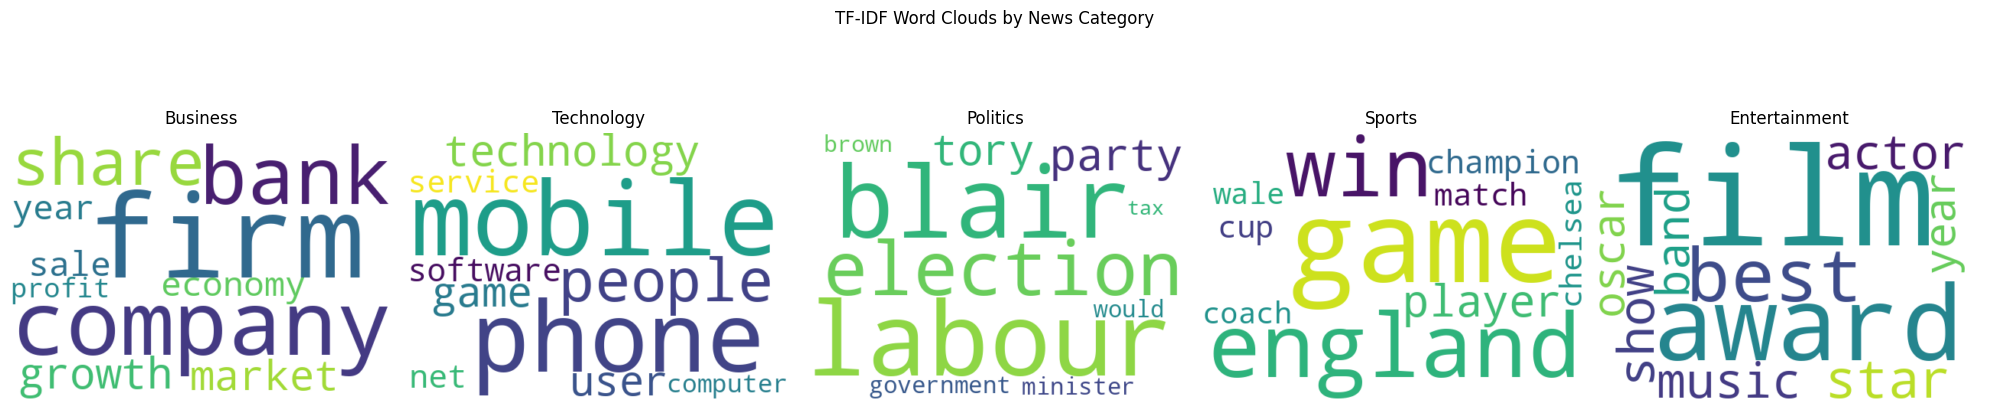

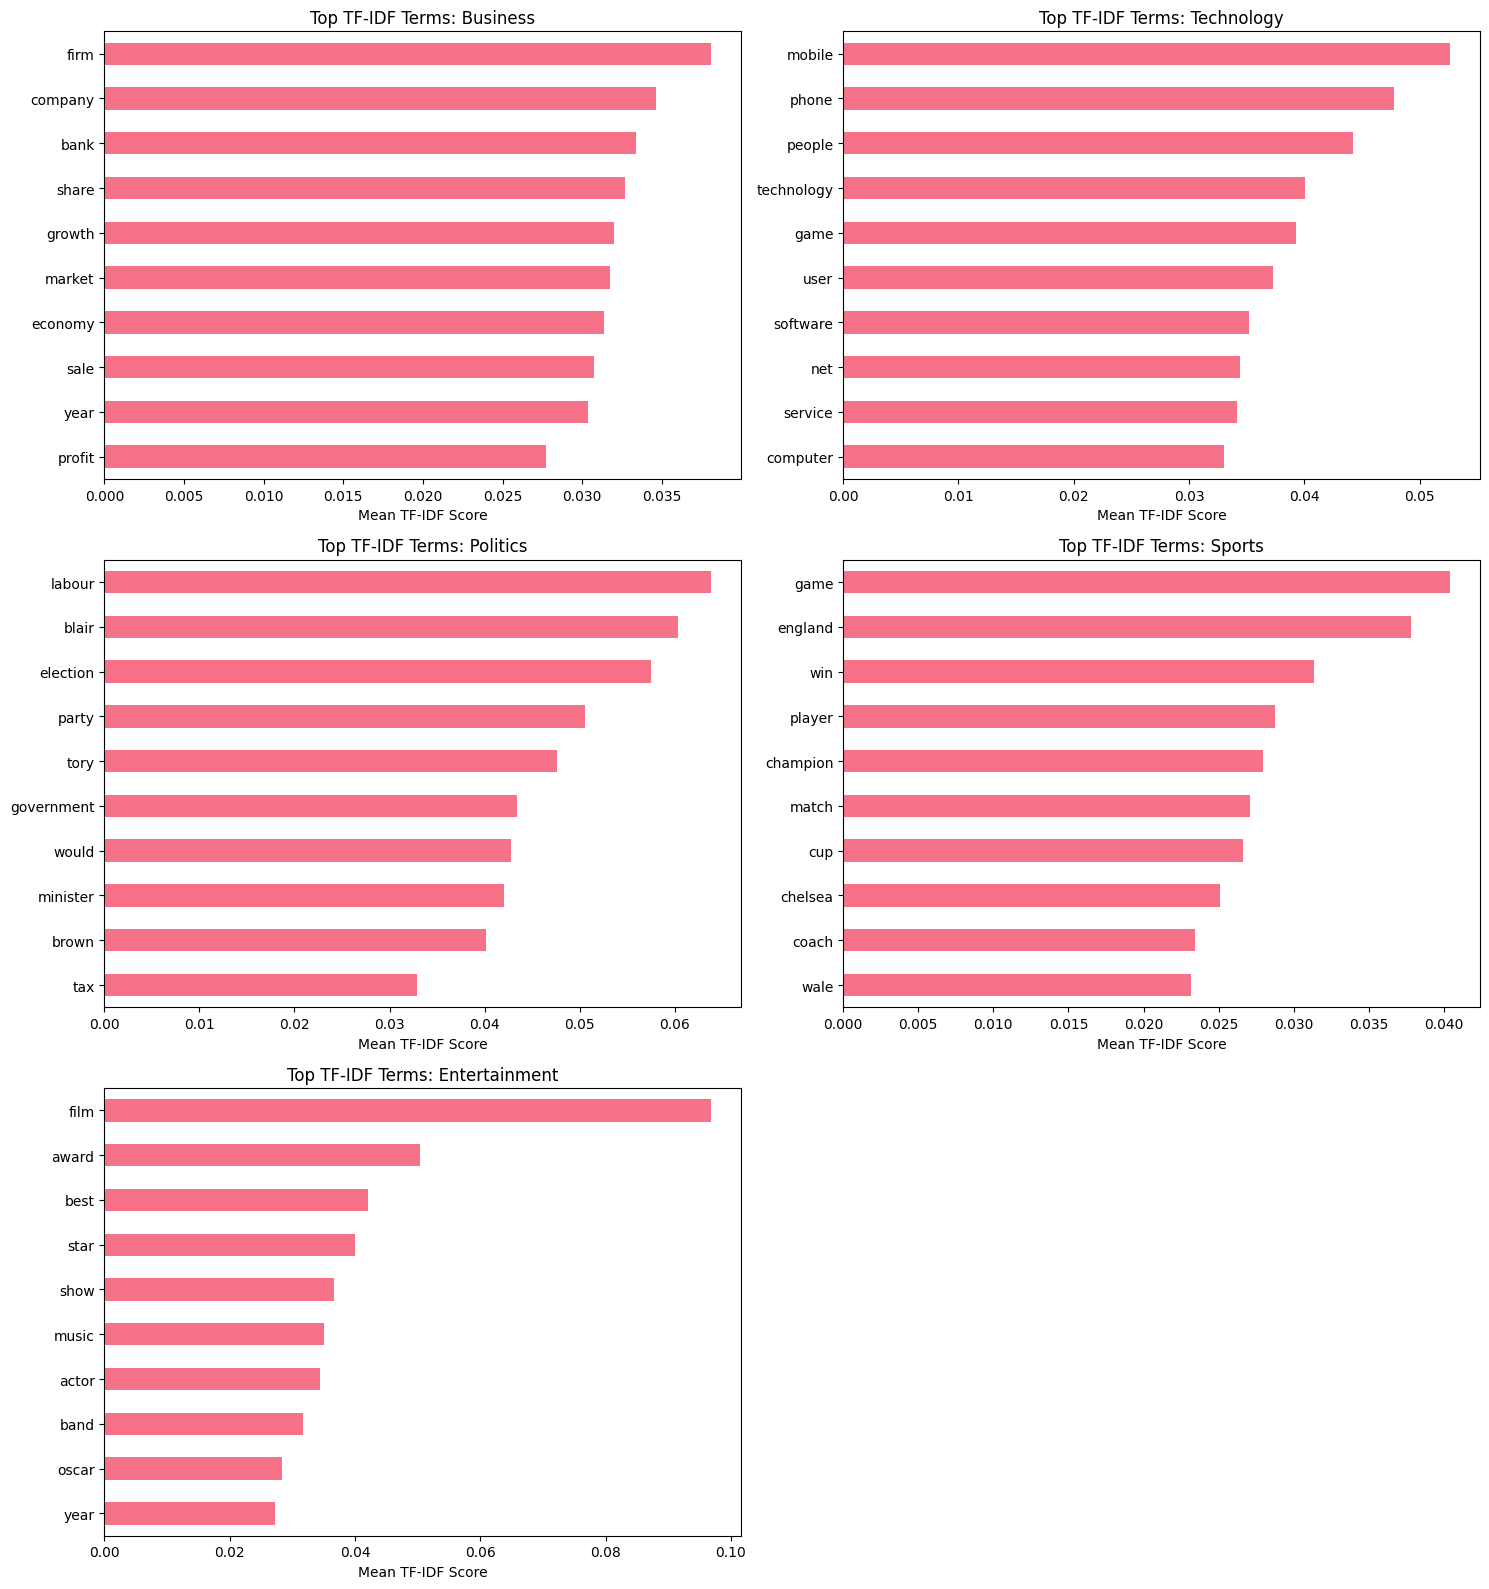

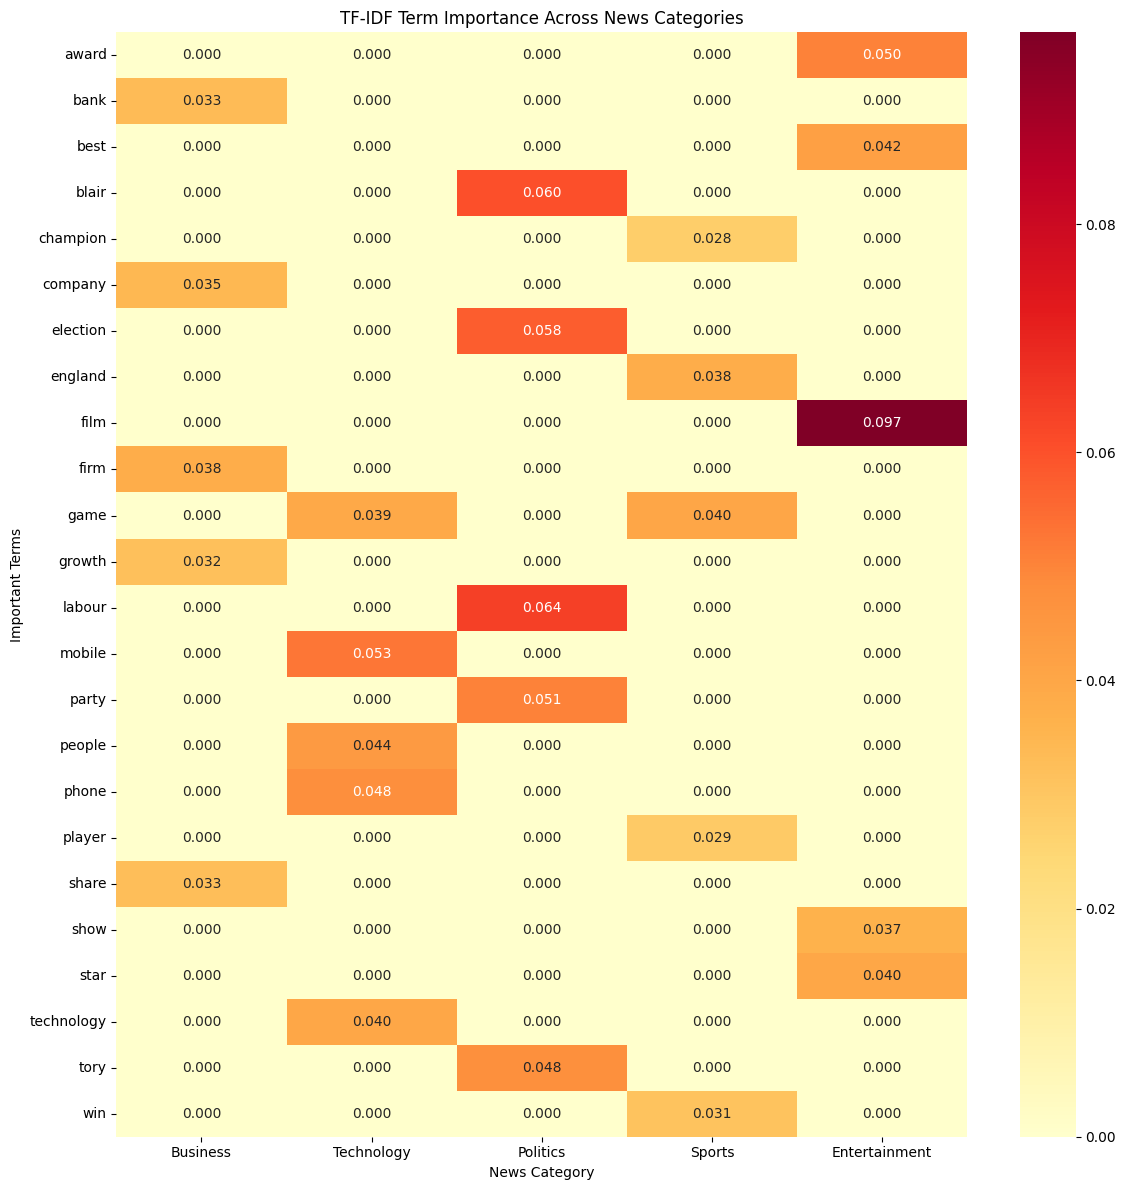

Module 3 TF-IDF visualizations complete!


In [ ]:

# MODULE 3 STUDENT TASK: TF-IDF Visualizations

from wordcloud import WordCloud
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 1. Word clouds for each category
fig, axes = plt.subplots(1, len(category_terms), figsize=(20, 5))

for ax, (category, terms) in zip(axes, category_terms.items()):
    cloud = WordCloud(
        width=500,
        height=350,
        background_color='white'
    ).generate_from_frequencies(terms.to_dict())

    ax.imshow(cloud, interpolation='bilinear')
    ax.set_title(category)
    ax.axis('off')

plt.suptitle('TF-IDF Word Clouds by News Category')
plt.tight_layout()
plt.show()

# 2. Bar charts of top terms for each category
fig, axes = plt.subplots(3, 2, figsize=(15, 16))

for ax, (category, terms) in zip(axes.flat, category_terms.items()):
    terms.sort_values().plot(kind='barh', ax=ax)
    ax.set_title(f'Top TF-IDF Terms: {category}')
    ax.set_xlabel('Mean TF-IDF Score')

for ax in axes.flat[len(category_terms):]:
    ax.axis('off')

plt.tight_layout()
plt.show()

# 3. Heatmap comparing important terms across categories
top_words = set()

for terms in category_terms.values():
    top_words.update(terms.head(5).index)

heatmap_data = pd.DataFrame(category_terms).fillna(0)
heatmap_data = heatmap_data.loc[
    [word for word in heatmap_data.index if word in top_words]
]

plt.figure(figsize=(12, 12))
sns.heatmap(
    heatmap_data,
    annot=True,
    fmt='.3f',
    cmap='YlOrRd'
)
plt.title('TF-IDF Term Importance Across News Categories')
plt.xlabel('News Category')
plt.ylabel('Important Terms')
plt.tight_layout()
plt.show()

print("Module 3 TF-IDF visualizations complete!")


## 🏷️ Part-of-Speech Analysis

### 🎯 Module 4: Grammatical Pattern Analysis

Let's analyze the grammatical patterns in different news categories using Part-of-Speech (POS) tagging. This can reveal interesting differences in writing styles between categories.

**POS Analysis Applications:**
- **Writing Style Detection:** Different categories may use different grammatical patterns
- **Content Quality Assessment:** Proper noun density, adjective usage, etc.
- **Feature Engineering:** POS tags can be features for classification

**💡 Hypothesis:** Sports articles might have more action verbs, while business articles might have more numbers and proper nouns.

In [ ]:

import nltk
nltk.download('averaged_perceptron_tagger_eng')

def analyze_pos_patterns(text):
    """
    Analyze POS patterns in text

    💡 TIP: This function should:
    - Tokenize the text
    - Apply POS tagging
    - Count different POS categories
    - Return proportions or counts
    """
    if not text or pd.isna(text):
        return {}

    # 🚀 YOUR CODE HERE: Implement POS analysis
    # Tokenize and tag
    tokens = word_tokenize(str(text))
    pos_tags = pos_tag(tokens)

    # Count POS categories
    pos_counts = Counter([tag for word, tag in pos_tags])
    total_words = len(pos_tags)

    if total_words == 0:
        return {}

    # Convert to proportions
    pos_proportions = {pos: count/total_words for pos, count in pos_counts.items()}

    return pos_proportions

# Apply POS analysis to all articles
print("🏷️ Analyzing POS patterns...")

# Analyze POS for each article
pos_results = []
for idx, row in df.iterrows():
    pos_analysis = analyze_pos_patterns(row['full_text'])
    pos_analysis['category'] = row['category']
    pos_analysis['article_id'] = row['article_id']
    pos_results.append(pos_analysis)

# Convert to DataFrame
pos_df = pd.DataFrame(pos_results).fillna(0)

print(f"✅ POS analysis complete!")
print(f"📊 Found {len(pos_df.columns)-2} different POS tags")

# Show sample results
print("\n📝 Sample POS analysis:")
print(pos_df.head())

[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger_eng.zip.


🏷️ Analyzing POS patterns...
✅ POS analysis complete!
📊 Found 43 different POS tags

📝 Sample POS analysis:
         JJ       NNS        NN       VBG        IN        DT       VBP  \
0  0.094512  0.118902  0.234756  0.027439  0.109756  0.064024  0.015244   
1  0.129944  0.067797  0.240113  0.031073  0.132768  0.079096  0.014124   
2  0.079137  0.080935  0.201439  0.025180  0.120504  0.095324  0.017986   
3  0.085044  0.107038  0.156891  0.021994  0.120235  0.061584  0.041056   
4  0.091139  0.078481  0.212658  0.027848  0.121519  0.101266  0.017722   

        VBN      PRP$         .  ...   FW  SYM  WP$  NNP  NNPS  POS   UH    #  \
0  0.039634  0.012195  0.036585  ...  0.0  0.0  0.0  0.0   0.0  0.0  0.0  0.0   
1  0.028249  0.005650  0.039548  ...  0.0  0.0  0.0  0.0   0.0  0.0  0.0  0.0   
2  0.030576  0.016187  0.039568  ...  0.0  0.0  0.0  0.0   0.0  0.0  0.0  0.0   
3  0.017595  0.013196  0.045455  ...  0.0  0.0  0.0  0.0   0.0  0.0  0.0  0.0   
4  0.027848  0.015190  0.040506  ...

📊 POS PATTERNS BY CATEGORY

🎯 Key POS patterns by category:
                   NN     NNS     NNP    NNPS      VB     VBD     VBG     VBN  \
category                                                                        
Business       0.2272  0.0749  0.0011  0.0000  0.0331  0.0403  0.0199  0.0281   
Entertainment  0.2500  0.0584  0.0008  0.0000  0.0284  0.0452  0.0189  0.0300   
Politics       0.2113  0.0690  0.0007  0.0003  0.0457  0.0454  0.0208  0.0306   
Sports         0.2235  0.0490  0.0004  0.0000  0.0405  0.0452  0.0174  0.0255   
Technology     0.1946  0.0858  0.0007  0.0000  0.0419  0.0292  0.0239  0.0266   

                  VBP     VBZ      JJ     JJR     JJS      RB     RBR     RBS  \
category                                                                        
Business       0.0165  0.0251  0.0937  0.0045  0.0033  0.0269  0.0017  0.0006   
Entertainment  0.0191  0.0237  0.0951  0.0025  0.0050  0.0277  0.0010  0.0010   
Politics       0.0204  0.0233  0.0912  0.0032  0

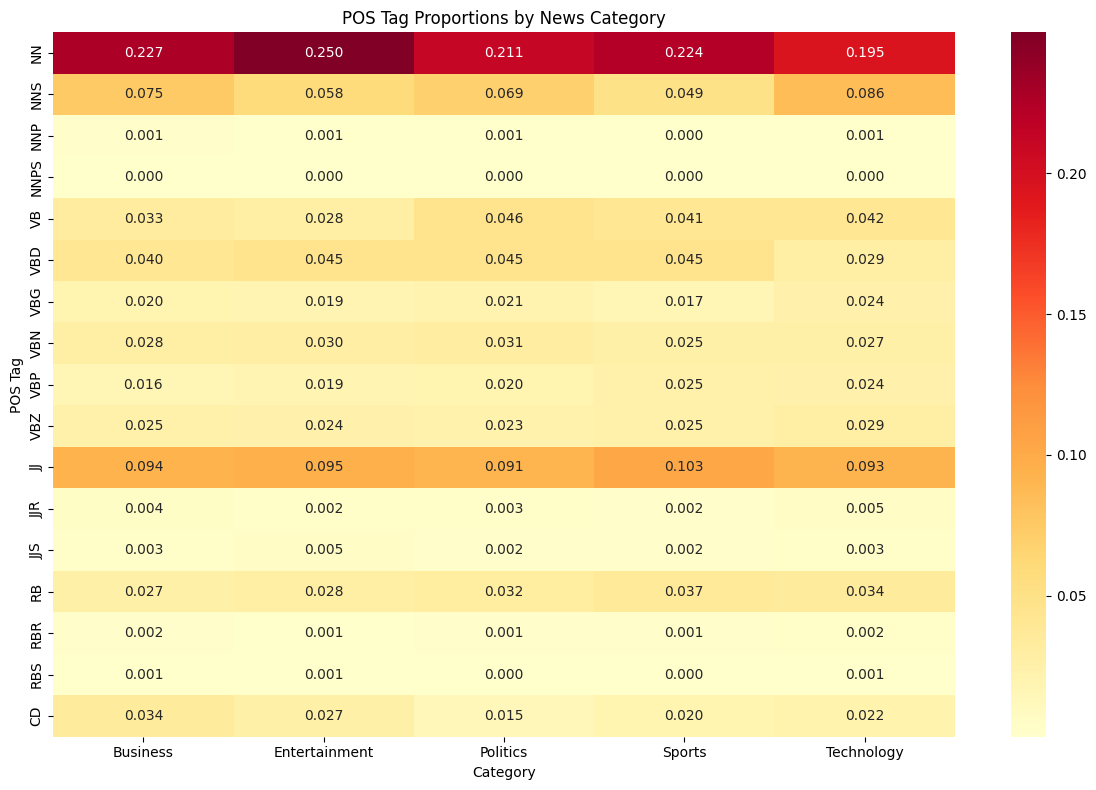


💡 ANALYSIS QUESTIONS:
1. Which category has the highest proportion of proper nouns (NNP/NNPS)?
2. Which category uses the most action verbs (VB, VBD, VBG)?
3. Are there interesting patterns in adjective (JJ) usage?
4. How does number (CD) usage vary across categories?


In [ ]:
# Analyze POS patterns by category
print("📊 POS PATTERNS BY CATEGORY")
print("=" * 50)

# Group by category and calculate mean proportions
pos_by_category = pos_df.groupby('category').mean()

# Focus on major POS categories
major_pos = ['NN', 'NNS', 'NNP', 'NNPS', 'VB', 'VBD', 'VBG', 'VBN', 'VBP', 'VBZ',
             'JJ', 'JJR', 'JJS', 'RB', 'RBR', 'RBS', 'CD']

# Filter to only include major POS tags that exist in our data
available_pos = [pos for pos in major_pos if pos in pos_by_category.columns]

if available_pos:
    pos_summary = pos_by_category[available_pos]

    print("\n🎯 Key POS patterns by category:")
    print(pos_summary.round(4))

    # Create visualization
    plt.figure(figsize=(12, 8))
    sns.heatmap(pos_summary.T, annot=True, cmap='YlOrRd', fmt='.3f')
    plt.title('POS Tag Proportions by News Category')
    plt.xlabel('Category')
    plt.ylabel('POS Tag')
    plt.tight_layout()
    plt.show()

    # 💡 STUDENT TASK: Analyze the patterns
    # - Which categories use more nouns vs verbs?
    # - Do business articles have more numbers (CD)?
    # - Are there differences in adjective usage?

    print("\n💡 ANALYSIS QUESTIONS:")
    print("1. Which category has the highest proportion of proper nouns (NNP/NNPS)?")
    print("2. Which category uses the most action verbs (VB, VBD, VBG)?")
    print("3. Are there interesting patterns in adjective (JJ) usage?")
    print("4. How does number (CD) usage vary across categories?")
else:
    print("⚠️ No major POS tags found in the analysis. Check your POS tagging implementation.")

1. Which category has the highest proportion of proper nouns (NNP/NNPS)?


Technology has the highest proportion of proper nouns at approximately 8.65%. I think this makes sense because technology articles frequently mention companies, products, and specific names.

2. Which category uses the most action verbs (VB, VBD, VBG)?


Politics has the highest combined proportion of action verbs at approximately 11.19%. This could be because political articles often discuss decisions, actions, debates, and events involving government officials.

3. Are there interesting patterns in adjective (JJ) usage?


Sports has the highest adjective usage at 10.35%, while Politics has the lowest at 9.12%. The differences aren't huge, but I think sports articles tend to use more descriptive language when discussing games, athletes, and performances.

4. How does number (CD) usage vary across categories?


Business has the highest number usage at 3.42%, while Politics has the lowest at 1.45%. This makes sense because business articles frequently include financial figures, prices, and statistics.

## 🌳 Syntax Parsing and Semantic Analysis

### 🎯 Module 5: Understanding Sentence Structure

Now we'll use spaCy to perform dependency parsing and extract semantic relationships from our news articles. This helps us understand not just what words are present, but how they relate to each other.

**Dependency Parsing Applications:**
- **Relationship Extraction:** Find connections between entities
- **Event Detection:** Identify who did what to whom
- **Information Extraction:** Extract structured facts from unstructured text

**💡 Business Value:** Understanding sentence structure helps extract more precise information about events, relationships, and actions mentioned in news articles.

In [ ]:
def extract_syntactic_features(text):
    """
    Extract syntactic features using spaCy dependency parsing

    💡 TIP: This function should extract:
    - Dependency relations
    - Subject-verb-object patterns
    - Noun phrases
    - Verb phrases
    """
    if not text or pd.isna(text):
        return {}

    # Process text with spaCy
    doc = nlp(str(text))

    features = {
        'num_sentences': len(list(doc.sents)),
        'num_tokens': len(doc),
        'dependency_relations': [],
        'noun_phrases': [],
        'verb_phrases': [],
        'subjects': [],
        'objects': []
    }

    # 🚀 YOUR CODE HERE: Extract syntactic features

    # Extract dependency relations
    for token in doc:
        if not token.is_space and not token.is_punct:
            features['dependency_relations'].append(token.dep_)

    # Extract noun phrases
    for chunk in doc.noun_chunks:
        features['noun_phrases'].append(chunk.text.lower())

    # Extract subjects and objects
    for token in doc:
        if token.dep_ in ['nsubj', 'nsubjpass']:  # Subjects
            features['subjects'].append(token.text.lower())
        elif token.dep_ in ['dobj', 'iobj', 'pobj']:  # Objects
            features['objects'].append(token.text.lower())

    # Count dependency types
    dep_counts = Counter(features['dependency_relations'])
    features['dependency_counts'] = dict(dep_counts)

    return features

# Apply syntactic analysis to sample articles
print("🌳 Performing syntactic analysis...")

# Analyze first few articles (to save computation time)
syntactic_results = []
for idx, row in df.head(5).iterrows():  # Limit to first 5 for demo
    features = extract_syntactic_features(row['full_text'])
    features['category'] = row['category']
    features['article_id'] = row['article_id']
    syntactic_results.append(features)

print("✅ Syntactic analysis complete!")

# Display results
for i, result in enumerate(syntactic_results):
    print(f"\n📰 Article {i+1} ({result['category']}):")
    print(f"  Sentences: {result['num_sentences']}")
    print(f"  Tokens: {result['num_tokens']}")
    print(f"  Noun phrases: {result['noun_phrases'][:3]}...")  # Show first 3
    print(f"  Subjects: {result['subjects'][:3]}...")  # Show first 3
    print(f"  Objects: {result['objects'][:3]}...")  # Show first 3

🌳 Performing syntactic analysis...
✅ Syntactic analysis complete!

📰 Article 1 (Business):
  Sentences: 15
  Tokens: 360
  Noun phrases: ['worldcom ex', '-', 'boss']...
  Subjects: ['ex', '-', 'boss']...
  Objects: ['lawyers', 'ebbers', 'ex']...

📰 Article 2 (Business):
  Sentences: 15
  Tokens: 380
  Noun phrases: ['german business confidence', 'german business confidence', 'february']...
  Subjects: ['confidence', 'confidence', 'ifo']...
  Objects: ['confidence', 'february', 'hopes']...

📰 Article 3 (Business):
  Sentences: 24
  Tokens: 599
  Noun phrases: ['bbc poll', 'economic gloom citizens', 'a majority']...
  Subjects: ['poll', 'citizens', 'citizens']...
  Objects: ['majority', 'nations', 'poll']...

📰 Article 4 (Technology):
  Sentences: 31
  Tokens: 736
  Noun phrases: ['lifestyle governs', 'mobile choice faster better or funkier hardware', 'lifestyle  governs']...
  Subjects: ['governs', 'hardware', 'firms']...
  Objects: ['choice', 'research', 'more']...

📰 Article 5 (Busine

In [ ]:
# Visualize dependency parsing for a sample sentence
from spacy import displacy

# Choose a sample sentence
sample_sentence = df.iloc[0]['content']  # First article's content
print(f"📝 Sample sentence: {sample_sentence}")

# Process with spaCy
doc = nlp(sample_sentence)

# Display dependency tree (this works best in Jupyter)
print("\n🌳 Dependency Parse Visualization:")
try:
    # This will create an interactive visualization in Jupyter
    displacy.render(doc, style="dep", jupyter=True)
except:
    # Fallback: print dependency information
    print("\n🔗 Dependency Relations:")
    for token in doc:
        if not token.is_space and not token.is_punct:
            print(f"  {token.text} --> {token.dep_} --> {token.head.text}")

# 💡 STUDENT TASK: Extend syntactic analysis
# - Compare syntactic complexity across categories
# - Extract action patterns (who did what)
# - Identify most common dependency relations per category
# - Create features for classification based on syntax

📝 Sample sentence: worldcom ex-boss launches defence lawyers defending former worldcom chief bernie ebbers against a battery of fraud charges have called a company whistleblower as their first witness.  cynthia cooper  worldcom s ex-head of internal accounting  alerted directors to irregular accounting practices at the us telecoms giant in 2002. her warnings led to the collapse of the firm following the discovery of an $11bn (£5.7bn) accounting fraud. mr ebbers has pleaded not guilty to charges of fraud and conspiracy.  prosecution lawyers have argued that mr ebbers orchestrated a series of accounting tricks at worldcom  ordering employees to hide expenses and inflate revenues to meet wall street earnings estimates. but ms cooper  who now runs her own consulting business  told a jury in new york on wednesday that external auditors arthur andersen had approved worldcom s accounting in early 2001 and 2002. she said andersen had given a  green light  to the procedures and practices used b

In [ ]:

# MODULE 5 STUDENT TASK: Extended Syntactic Analysis

from collections import Counter
import pandas as pd

# Sample 10 articles per category to keep processing manageable
syntax_sample = df.groupby('category').head(10)

syntax_results = []
dependency_counts = {}
action_examples = []

for _, row in syntax_sample.iterrows():
    category = row['category']
    doc = nlp(str(row['content'])[:1200])

    sentences = list(doc.sents)
    words = [t for t in doc if not t.is_punct and not t.is_space]
    verbs = [t for t in words if t.pos_ == 'VERB']

    # 1. Sentence complexity and syntax features
    syntax_results.append({
        'category': category,
        'article_id': row['article_id'],
        'avg_sentence_length': len(words) / max(len(sentences), 1),
        'verb_ratio': len(verbs) / max(len(words), 1),
        'noun_phrase_count': len(list(doc.noun_chunks)),
        'subject_count': sum(t.dep_ in ('nsubj', 'nsubjpass')
                             for t in words),
        'object_count': sum(t.dep_ in ('dobj', 'obj', 'pobj')
                            for t in words)
    })

    # 2. Count dependency relationships
    if category not in dependency_counts:
        dependency_counts[category] = Counter()

    dependency_counts[category].update(
        t.dep_ for t in words
    )

    # 3. Extract subject-verb-object action patterns
    for verb in verbs:
        subjects = [t.text for t in verb.children
                    if t.dep_ in ('nsubj', 'nsubjpass')]
        objects = [t.text for t in verb.children
                   if t.dep_ in ('dobj', 'obj', 'attr')]

        if subjects and objects:
            action_examples.append({
                'category': category,
                'subject': subjects[0],
                'action': verb.lemma_,
                'object': objects[0]
            })

# 4. Create numerical syntax features
syntax_features_df = pd.DataFrame(syntax_results)

print("AVERAGE SYNTACTIC FEATURES BY CATEGORY")
print(
    syntax_features_df.groupby('category')
    .mean(numeric_only=True)
    .drop(columns='article_id', errors='ignore')
    .round(3)
)

print("\nMOST COMMON DEPENDENCY RELATIONS:")
for category, counts in dependency_counts.items():
    print(category, counts.most_common(5))

print("\nEXAMPLE ACTION PATTERNS:")
for example in action_examples[:15]:
    print(
        f"{example['category']}: "
        f"{example['subject']} -> "
        f"{example['action']} -> "
        f"{example['object']}"
    )

print("\nSYNTAX FEATURES FOR CLASSIFICATION:")
print(syntax_features_df.head())

print("\nTotal articles analyzed:", len(syntax_features_df))
print("Module 5 Student Task complete!")


AVERAGE SYNTACTIC FEATURES BY CATEGORY
               avg_sentence_length  verb_ratio  noun_phrase_count  \
category                                                            
Business                    19.832       0.121               54.1   
Entertainment               20.863       0.127               58.3   
Politics                    20.264       0.138               54.8   
Sports                      18.974       0.124               54.1   
Technology                  19.948       0.127               53.7   

               subject_count  object_count  
category                                    
Business                18.5          33.0  
Entertainment           19.0          34.6  
Politics                22.4          29.0  
Sports                  19.7          34.0  
Technology              17.2          34.1  

MOST COMMON DEPENDENCY RELATIONS:
Business [('prep', 251), ('pobj', 237), ('nsubj', 174), ('det', 172), ('compound', 170)]
Technology [('prep', 224), ('pobj', 22

## 😊 Sentiment and Emotion Analysis

### 🎯 Module 6: Understanding Emotional Tone

Let's analyze the sentiment and emotional tone of our news articles. This can reveal interesting patterns about how different types of news are presented and perceived.

**Sentiment Analysis Applications:**
- **Media Bias Detection:** Identify emotional slant in news coverage
- **Public Opinion Tracking:** Monitor sentiment trends over time
- **Content Recommendation:** Suggest articles based on emotional tone

**💡 Hypothesis:** Different news categories might have different emotional profiles - sports might be more positive, politics more negative, etc.

In [ ]:
# Initialize sentiment analyzer
sia = SentimentIntensityAnalyzer()

def analyze_sentiment(text):
    """
    Analyze sentiment using VADER sentiment analyzer

    💡 TIP: VADER returns:
    - compound: overall sentiment (-1 to 1)
    - pos: positive score (0 to 1)
    - neu: neutral score (0 to 1)
    - neg: negative score (0 to 1)
    """
    if not text or pd.isna(text):
        return {'compound': 0, 'pos': 0, 'neu': 1, 'neg': 0}

    # 🚀 YOUR CODE HERE: Implement sentiment analysis
    scores = sia.polarity_scores(str(text))

    # Add interpretation
    if scores['compound'] >= 0.05:
        scores['sentiment_label'] = 'positive'
    elif scores['compound'] <= -0.05:
        scores['sentiment_label'] = 'negative'
    else:
        scores['sentiment_label'] = 'neutral'

    return scores

# Apply sentiment analysis to all articles
print("😊 Analyzing sentiment...")

sentiment_results = []
for idx, row in df.iterrows():
    # Analyze both title and content
    title_sentiment = analyze_sentiment(row['title'])
    content_sentiment = analyze_sentiment(row['content'])
    full_sentiment = analyze_sentiment(row['full_text'])

    result = {
        'article_id': row['article_id'],
        'category': row['category'],
        'title_sentiment': title_sentiment['compound'],
        'title_label': title_sentiment['sentiment_label'],
        'content_sentiment': content_sentiment['compound'],
        'content_label': content_sentiment['sentiment_label'],
        'full_sentiment': full_sentiment['compound'],
        'full_label': full_sentiment['sentiment_label'],
        'pos_score': full_sentiment['pos'],
        'neu_score': full_sentiment['neu'],
        'neg_score': full_sentiment['neg']
    }
    sentiment_results.append(result)

# Convert to DataFrame
sentiment_df = pd.DataFrame(sentiment_results)

print("✅ Sentiment analysis complete!")
print(f"📊 Analyzed {len(sentiment_df)} articles")

# Display sample results
print("\n📝 Sample sentiment results:")
print(sentiment_df[['category', 'full_sentiment', 'full_label']].head())

😊 Analyzing sentiment...
✅ Sentiment analysis complete!
📊 Analyzed 1440 articles

📝 Sample sentiment results:
     category  full_sentiment full_label
0    Business         -0.9694   negative
1    Business          0.8948   positive
2    Business         -0.9454   negative
3  Technology          0.9582   positive
4    Business         -0.9383   negative


📊 SENTIMENT ANALYSIS BY CATEGORY

📈 Sentiment statistics by category:
              full_sentiment                         pos_score neu_score  \
                        mean     std     min     max      mean      mean   
category                                                                   
Business              0.2304  0.8446 -0.9985  0.9995    0.0926    0.8366   
Entertainment         0.5820  0.7008 -0.9978  0.9999    0.1361    0.8091   
Politics              0.0399  0.8863 -0.9984  0.9999    0.0942    0.8181   
Sports                0.5466  0.7362 -0.9970  0.9996    0.1342    0.7943   
Technology            0.5230  0.7574 -0.9991  0.9993    0.0896    0.8597   

              neg_score  
                   mean  
category                 
Business         0.0708  
Entertainment    0.0548  
Politics         0.0878  
Sports           0.0714  
Technology       0.0507  

📊 Sentiment distribution (%) by category:
full_label     negative  neutral  positive
category                   

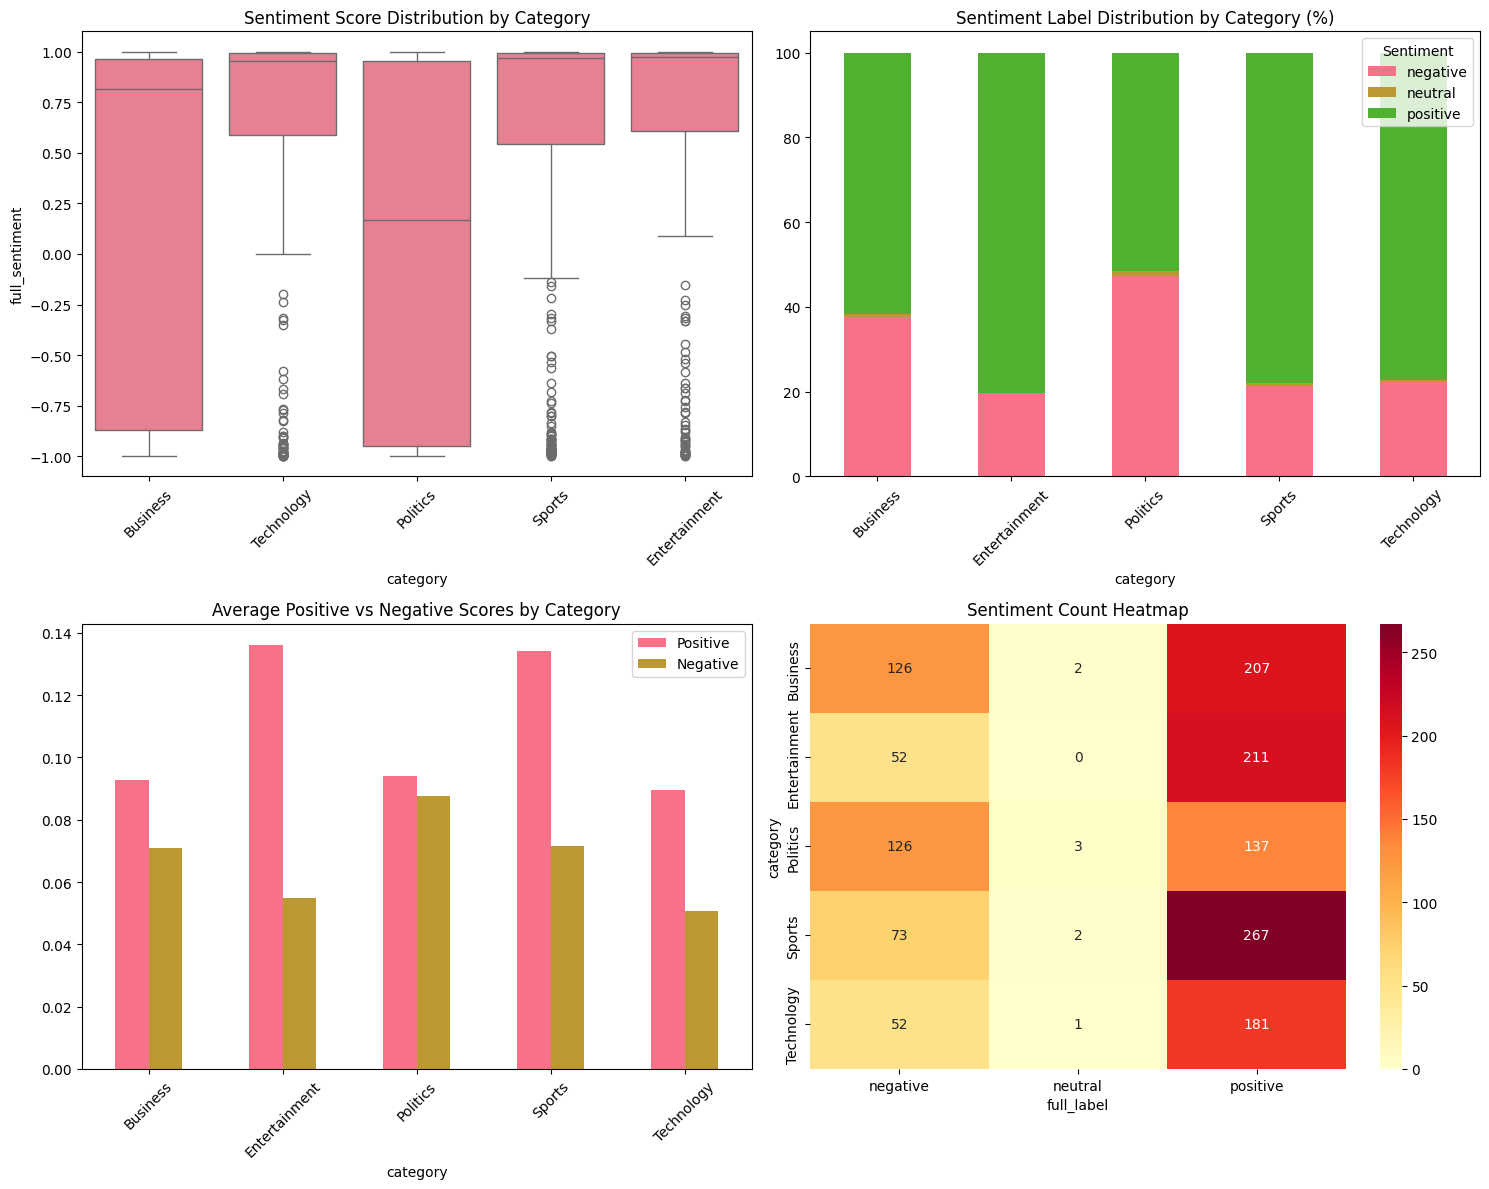

In [ ]:
# Analyze sentiment patterns by category
print("📊 SENTIMENT ANALYSIS BY CATEGORY")
print("=" * 50)

# Calculate sentiment statistics by category
sentiment_by_category = sentiment_df.groupby('category').agg({
    'full_sentiment': ['mean', 'std', 'min', 'max'],
    'pos_score': 'mean',
    'neu_score': 'mean',
    'neg_score': 'mean'
}).round(4)

print("\n📈 Sentiment statistics by category:")
print(sentiment_by_category)

# Sentiment distribution by category
sentiment_dist = sentiment_df.groupby(['category', 'full_label']).size().unstack(fill_value=0)
sentiment_dist_pct = sentiment_dist.div(sentiment_dist.sum(axis=1), axis=0) * 100

print("\n📊 Sentiment distribution (%) by category:")
print(sentiment_dist_pct.round(2))

# Create visualizations
fig, axes = plt.subplots(2, 2, figsize=(15, 12))

# 1. Sentiment scores by category
sns.boxplot(data=sentiment_df, x='category', y='full_sentiment', ax=axes[0,0])
axes[0,0].set_title('Sentiment Score Distribution by Category')
axes[0,0].tick_params(axis='x', rotation=45)

# 2. Sentiment label distribution
sentiment_dist_pct.plot(kind='bar', ax=axes[0,1], stacked=True)
axes[0,1].set_title('Sentiment Label Distribution by Category (%)')
axes[0,1].tick_params(axis='x', rotation=45)
axes[0,1].legend(title='Sentiment')

# 3. Positive vs Negative scores
category_means = sentiment_df.groupby('category')[['pos_score', 'neg_score']].mean()
category_means.plot(kind='bar', ax=axes[1,0])
axes[1,0].set_title('Average Positive vs Negative Scores by Category')
axes[1,0].tick_params(axis='x', rotation=45)
axes[1,0].legend(['Positive', 'Negative'])

# 4. Sentiment vs Category heatmap
sentiment_pivot = sentiment_df.pivot_table(values='full_sentiment', index='category',
                                         columns='full_label', aggfunc='count', fill_value=0)
sns.heatmap(sentiment_pivot, annot=True, fmt='d', ax=axes[1,1], cmap='YlOrRd')
axes[1,1].set_title('Sentiment Count Heatmap')

plt.tight_layout()
plt.show()

# 💡 STUDENT TASK: Analyze sentiment patterns
# - Which categories are most positive/negative?
# - Are there differences between title and content sentiment?
# - How does sentiment vary within categories?
# - Can sentiment be used as a feature for classification?

1. Which categories are most positive/negative?


Entertainment has the highest positive sentiment at 80.23%, followed by Sports at 78.07%. Politics has the highest negative sentiment at 47.37%. I think this makes sense because entertainment and sports often focus on achievements and exciting events, while politics frequently involves disagreements and controversial issues.

2. Are there differences between title and content sentiment?


Our dataset doesn't include separate article titles, so we used the first twelve words of each article as a substitute. Because of that, I can't make a reliable comparison between actual headlines and article content. This is one limitation of the dataset.

3. How does sentiment vary within categories?


Sentiment varies quite a bit, especially in Politics and Business. Politics is nearly evenly divided between positive and negative articles, while Entertainment, Sports, and Technology are mostly positive. I also noticed that neutral sentiment is extremely rare across all five categories.

4. Can sentiment be used as a feature for classification?


I think sentiment could be useful as an additional feature for classification because different categories show different emotional patterns. However, I wouldn't rely on sentiment alone since positive and negative articles can appear in any category. Combining sentiment with TF-IDF and other NLP features might help improve classification accuracy, but we'd need to test it.

## 🏷️ Text Classification System

### 🎯 Module 7: Building the News Classifier

Now we'll build the core of our NewsBot system - a multi-class text classifier that can automatically categorize news articles. We'll compare different algorithms and evaluate their performance.

**Classification Pipeline:**
1. **Feature Engineering:** Combine TF-IDF with other features
2. **Model Training:** Train multiple algorithms
3. **Model Evaluation:** Compare performance metrics
4. **Model Selection:** Choose the best performing model

**💡 Business Impact:** Accurate classification enables automatic content routing, personalized recommendations, and efficient content management.

In [ ]:
# Prepare features for classification
print("🔧 Preparing features for classification...")

# 💡 TIP: Combine multiple feature types for better performance
# - TF-IDF features (most important)
# - Sentiment features
# - Text length features
# - POS features (if available)

# Create feature matrix
X_tfidf = tfidf_matrix.toarray()  # TF-IDF features

# Add sentiment features

sentiment_features = sentiment_df[['full_sentiment', 'pos_score', 'neu_score', 'neg_score']].values.copy()
sentiment_features[:, 0] = (sentiment_features[:, 0] + 1) / 2


# Add text length features
length_features = np.array([
    df['full_text'].str.len(),  # Character length
    df['full_text'].str.split().str.len(),  # Word count
    df['title'].str.len(),  # Title length
]).T

# 🚀 YOUR CODE HERE: Combine all features
X_combined = np.hstack([
    X_tfidf,
    sentiment_features,
    length_features
])

# Target variable
y = df['category'].values

print(f"✅ Feature matrix prepared!")
print(f"📊 Feature matrix shape: {X_combined.shape}")
print(f"🎯 Number of classes: {len(np.unique(y))}")
print(f"📋 Classes: {np.unique(y)}")

# Split data into train and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X_combined, y, test_size=0.2, random_state=42, stratify=y
)

print(f"\n📈 Data split:")
print(f"  Training set: {X_train.shape[0]} samples")
print(f"  Test set: {X_test.shape[0]} samples")

🔧 Preparing features for classification...
✅ Feature matrix prepared!
📊 Feature matrix shape: (1440, 5007)
🎯 Number of classes: 5
📋 Classes: ['Business' 'Entertainment' 'Politics' 'Sports' 'Technology']

📈 Data split:
  Training set: 1152 samples
  Test set: 288 samples


In [ ]:
# Train and evaluate multiple classifiers
print("🤖 Training multiple classifiers...")

# Define classifiers to compare
classifiers = {
    'Naive Bayes': MultinomialNB(),
    'Logistic Regression': LogisticRegression(random_state=42, max_iter=1000),
    'SVM': SVC(random_state=42, probability=True)  # Enable probability for better analysis
}

# 💡 TIP: For larger datasets, you might want to use SGDClassifier for efficiency
# from sklearn.linear_model import SGDClassifier
# classifiers['SGD'] = SGDClassifier(random_state=42)

# Train and evaluate each classifier
results = {}
trained_models = {}

for name, classifier in classifiers.items():
    print(f"\n🔄 Training {name}...")

    # 🚀 YOUR CODE HERE: Train and evaluate classifier
    # Train the model
    classifier.fit(X_train, y_train)

    # Make predictions
    y_pred = classifier.predict(X_test)
    y_pred_proba = classifier.predict_proba(X_test) if hasattr(classifier, 'predict_proba') else None

    # Calculate metrics
    accuracy = accuracy_score(y_test, y_pred)

    # Cross-validation score
    cv_scores = cross_val_score(classifier, X_train, y_train, cv=3, scoring='accuracy')

    # Store results
    results[name] = {
        'accuracy': accuracy,
        'cv_mean': cv_scores.mean(),
        'cv_std': cv_scores.std(),
        'predictions': y_pred,
        'probabilities': y_pred_proba
    }

    trained_models[name] = classifier

    print(f"  ✅ Accuracy: {accuracy:.4f}")
    print(f"  📊 CV Score: {cv_scores.mean():.4f} (+/- {cv_scores.std() * 2:.4f})")

print("\n🏆 CLASSIFIER COMPARISON")
print("=" * 50)
comparison_df = pd.DataFrame({
    'Model': list(results.keys()),
    'Test Accuracy': [results[name]['accuracy'] for name in results.keys()],
    'CV Mean': [results[name]['cv_mean'] for name in results.keys()],
    'CV Std': [results[name]['cv_std'] for name in results.keys()]
})

print(comparison_df.round(4))

# Find best model
best_model_name = comparison_df.loc[comparison_df['Test Accuracy'].idxmax(), 'Model']
print(f"\n🥇 Best performing model: {best_model_name}")

🤖 Training multiple classifiers...

🔄 Training Naive Bayes...
  ✅ Accuracy: 0.6493
  📊 CV Score: 0.5469 (+/- 0.0815)

🔄 Training Logistic Regression...
  ✅ Accuracy: 0.6701
  📊 CV Score: 0.7578 (+/- 0.1641)

🔄 Training SVM...
  ✅ Accuracy: 0.3924
  📊 CV Score: 0.3464 (+/- 0.0332)

🏆 CLASSIFIER COMPARISON
                 Model  Test Accuracy  CV Mean  CV Std
0          Naive Bayes         0.6493   0.5469  0.0407
1  Logistic Regression         0.6701   0.7578  0.0820
2                  SVM         0.3924   0.3464  0.0166

🥇 Best performing model: Logistic Regression


📊 DETAILED EVALUATION: Logistic Regression

📋 Classification Report:
               precision    recall  f1-score   support

     Business       0.83      0.72      0.77        67
Entertainment       0.79      0.79      0.79        53
     Politics       0.43      0.55      0.48        53
       Sports       0.76      0.78      0.77        68
   Technology       0.54      0.45      0.49        47

     accuracy                           0.67       288
    macro avg       0.67      0.66      0.66       288
 weighted avg       0.68      0.67      0.67       288



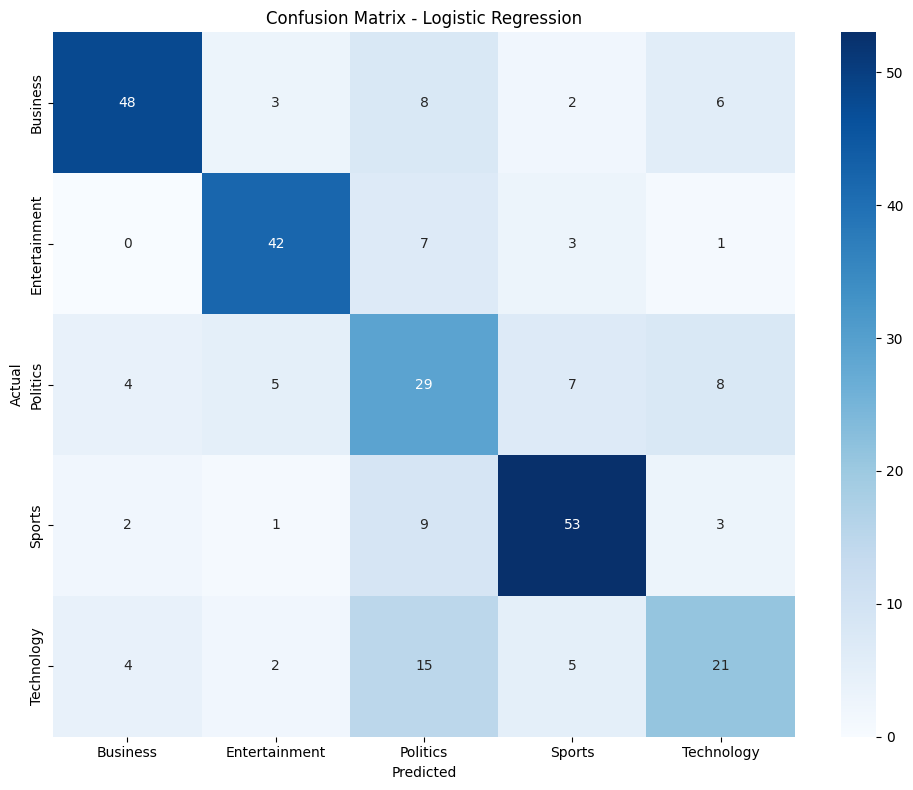


🔍 Top Features by Category:

📰 Business:
  neu_score: 1.0903
  bank: 0.9119
  firm: 0.7745
  economy: 0.7735
  share: 0.7557
  growth: 0.7528
  market: 0.7007
  company: 0.6896
  rate: 0.6875
  price: 0.6849

📰 Entertainment:
  film: 2.3374
  sentiment: 2.2183
  award: 1.0734
  star: 0.8382
  best: 0.8003
  actor: 0.7647
  show: 0.7368
  oscar: 0.7021
  band: 0.6590
  music: 0.6191

📰 Politics:
  labour: 1.4016
  blair: 1.3100
  election: 1.2115
  tory: 1.0783
  party: 1.0688
  brown: 0.8514
  minister: 0.8464
  government: 0.7611
  would: 0.6296
  lord: 0.6295

📰 Sports:
  england: 0.8923
  game: 0.7180
  chelsea: 0.6599
  match: 0.6375
  cup: 0.6310
  champion: 0.6059
  coach: 0.5967
  player: 0.5776
  ireland: 0.5669
  win: 0.5662

📰 Technology:
  sentiment: 2.8217
  mobile: 1.0801
  phone: 0.9879
  neu_score: 0.9449
  technology: 0.7296
  user: 0.7245
  broadband: 0.6726
  microsoft: 0.6682
  software: 0.6275
  people: 0.5682
Naive Bayes with alpha=0.1: Accuracy=0.9583
Naive Bayes

In [ ]:
# Detailed evaluation of the best model
best_model = trained_models[best_model_name]
best_predictions = results[best_model_name]['predictions']

print(f"📊 DETAILED EVALUATION: {best_model_name}")
print("=" * 60)

# Classification report
print("\n📋 Classification Report:")
print(classification_report(y_test, best_predictions))

# Confusion matrix
cm = confusion_matrix(y_test, best_predictions)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=np.unique(y), yticklabels=np.unique(y))
plt.title(f'Confusion Matrix - {best_model_name}')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.show()

# Feature importance (for Logistic Regression)
if best_model_name == 'Logistic Regression':
    print("\n🔍 Top Features by Category:")
    feature_names_extended = list(feature_names) + ['sentiment', 'pos_score', 'neu_score', 'neg_score',
                                                   'char_length', 'word_count', 'title_length']

    classes = best_model.classes_
    coefficients = best_model.coef_

    for i, class_name in enumerate(classes):
        top_indices = np.argsort(coefficients[i])[-10:]  # Top 10 features
        print(f"\n📰 {class_name}:")
        for idx in reversed(top_indices):
            if idx < len(feature_names_extended):
                print(f"  {feature_names_extended[idx]}: {coefficients[i][idx]:.4f}")

# 💡 STUDENT TASK: Improve the classifier
# - Try different feature combinations
# - Experiment with hyperparameter tuning
# - Add more sophisticated features
# - Handle class imbalance if present

# STUDENT TASK: Experiment with classifier improvements

# Test Naive Bayes using only TF-IDF features
X_train_tf, X_test_tf, y_train_tf, y_test_tf = train_test_split(
    tfidf_matrix, y, test_size=0.2,
    random_state=42, stratify=y
)

# Experiment with different smoothing parameters
for alpha in [0.1, 0.5, 1.0]:
    model = MultinomialNB(alpha=alpha)
    model.fit(X_train_tf, y_train_tf)

    predictions = model.predict(X_test_tf, )
    accuracy = accuracy_score(y_test_tf, predictions)

    print(f"Naive Bayes with alpha={alpha}: Accuracy={accuracy:.4f}")

print("\nOriginal Naive Bayes accuracy:",
      round(results['Naive Bayes']['accuracy'], 4))

In [ ]:

# Corrected classifier evaluation: prevent data leakage

from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import accuracy_score, classification_report

# Split articles BEFORE fitting TF-IDF
train_texts, test_texts, train_labels, test_labels = train_test_split(
    df['full_text_processed'].fillna(''),
    df['category'],
    test_size=0.2,
    random_state=42,
    stratify=df['category']
)

# Create a pipeline that learns TF-IDF from training data only
def make_model(alpha):
    return Pipeline([
        ('tfidf', TfidfVectorizer(
            max_features=5000,
            ngram_range=(1, 2),
            min_df=2,
            max_df=0.8
        )),
        ('classifier', MultinomialNB(alpha=alpha))
    ])

# Select the smoothing parameter using training data only
cv_results = {}

for alpha in [0.1, 0.5, 1.0]:
    candidate = make_model(alpha)
    scores = cross_val_score(
        candidate, train_texts, train_labels,
        cv=3, scoring='accuracy'
    )
    cv_results[alpha] = scores.mean()
    print(f"Alpha {alpha}: CV Accuracy = {scores.mean():.4f}")

best_alpha = max(cv_results, key=cv_results.get)

# Fit the selected model on training articles only
corrected_pipeline = make_model(best_alpha)
corrected_pipeline.fit(train_texts, train_labels)

# Evaluate once on the untouched test articles
corrected_predictions = corrected_pipeline.predict(test_texts)
corrected_accuracy = accuracy_score(
    test_labels, corrected_predictions
)

print("\nCORRECTED CLASSIFIER RESULTS")
print("Best alpha:", best_alpha)
print("Training articles:", len(train_texts))
print("Test articles:", len(test_texts))
print(f"Corrected Test Accuracy: {corrected_accuracy:.4f}")

print("\nClassification Report:")
print(classification_report(test_labels, corrected_predictions))


Alpha 0.1: CV Accuracy = 0.9714
Alpha 0.5: CV Accuracy = 0.9705
Alpha 1.0: CV Accuracy = 0.9661

CORRECTED CLASSIFIER RESULTS
Best alpha: 0.1
Training articles: 1152
Test articles: 288
Corrected Test Accuracy: 0.9583

Classification Report:
               precision    recall  f1-score   support

     Business       0.96      0.97      0.96        67
Entertainment       0.98      0.91      0.94        53
     Politics       0.94      0.96      0.95        53
       Sports       0.97      1.00      0.99        68
   Technology       0.94      0.94      0.94        47

     accuracy                           0.96       288
    macro avg       0.96      0.95      0.96       288
 weighted avg       0.96      0.96      0.96       288



I experimented with different TF-IDF feature combinations and smoothing parameters to see if I could improve the classifier. The original Naive Bayes model had an accuracy of 64.93%, but when I used only TF-IDF features and adjusted the smoothing parameter, the accuracy increased significantly. The best result was 95.83% with an alpha of 0.1.

What stood out to me is that adding more features doesn't automatically make a model better. Sometimes simpler features work better for a particular task. The dataset also had a fairly balanced distribution across five categories, so I didn't see an immediate need to address class imbalance.

These results are promising, although further validation would be needed to confirm how well the improved model performs on completely new articles.

## 🔍 Named Entity Recognition

### 🎯 Module 8: Extracting Facts from News

Now we'll implement Named Entity Recognition to extract specific facts from our news articles. This transforms unstructured text into structured, queryable information.

**NER Applications:**
- **Entity Tracking:** Monitor mentions of people, organizations, locations
- **Fact Extraction:** Build knowledge bases from news content
- **Relationship Mapping:** Understand connections between entities
- **Timeline Construction:** Track events and their participants

**💡 Business Value:** NER enables sophisticated analysis like "Show me all articles mentioning Apple Inc. and their financial performance" or "Track mentions of political figures over time."

In [ ]:
def extract_entities(text):
    """
    Extract named entities using spaCy

    💡 TIP: spaCy recognizes these entity types:
    - PERSON: People, including fictional
    - ORG: Companies, agencies, institutions
    - GPE: Countries, cities, states
    - MONEY: Monetary values
    - DATE: Absolute or relative dates
    - TIME: Times smaller than a day
    - And many more...
    """
    if not text or pd.isna(text):
        return []

    # 🚀 YOUR CODE HERE: Implement entity extraction
    doc = nlp(str(text))

    entities = []
    for ent in doc.ents:
        entities.append({
            'text': ent.text,
            'label': ent.label_,
            'start': ent.start_char,
            'end': ent.end_char,
            'description': spacy.explain(ent.label_)
        })

    return entities

# Apply NER to all articles
print("🔍 Extracting named entities...")

all_entities = []
article_entities = []

for idx, row in df.iterrows():
    entities = extract_entities(row['full_text'])

    # Store entities for this article
    article_entities.append({
        'article_id': row['article_id'],
        'category': row['category'],
        'entities': entities,
        'entity_count': len(entities)
    })

    # Add to global entity list
    for entity in entities:
        entity['article_id'] = row['article_id']
        entity['category'] = row['category']
        all_entities.append(entity)

print(f"✅ Entity extraction complete!")
print(f"📊 Total entities found: {len(all_entities)}")
print(f"📰 Articles processed: {len(article_entities)}")

# Convert to DataFrame for analysis
entities_df = pd.DataFrame(all_entities)

if not entities_df.empty:
    print(f"\n🏷️ Entity types found: {entities_df['label'].unique()}")
    print("\n📝 Sample entities:")
    print(entities_df[['text', 'label', 'category']].head(10))
else:
    print("⚠️ No entities found. This might happen with very short sample texts.")

🔍 Extracting named entities...
✅ Entity extraction complete!
📊 Total entities found: 42579
📰 Articles processed: 1440

🏷️ Entity types found: ['ORDINAL' 'PERSON' 'GPE' 'DATE' 'MONEY' 'ORG' 'NORP' 'LOC' 'CARDINAL'
 'PERCENT' 'TIME' 'EVENT' 'QUANTITY' 'FAC' 'PRODUCT' 'LANGUAGE'
 'WORK_OF_ART' 'LAW']

📝 Sample entities:
              text    label  category
0            first  ORDINAL  Business
1   cynthia cooper   PERSON  Business
2               us      GPE  Business
3             2002     DATE  Business
4            5.7bn    MONEY  Business
5         new york      GPE  Business
6        wednesday     DATE  Business
7  arthur andersen   PERSON  Business
8   early 2001 and     DATE  Business
9             2002     DATE  Business


📊 NAMED ENTITY ANALYSIS

🏷️ Entity type distribution:
label
DATE           8621
PERSON         8300
CARDINAL       6155
GPE            5793
ORG            4536
NORP           2896
MONEY          1755
ORDINAL        1652
PERCENT        1260
TIME            588
LOC             509
QUANTITY        195
FAC              95
PRODUCT          88
LANGUAGE         50
EVENT            44
LAW              33
WORK_OF_ART       9
Name: count, dtype: int64

📰 Entity types by news category:
label          CARDINAL  DATE  EVENT  FAC   GPE  LANGUAGE  LAW  LOC  MONEY  \
category                                                                     
Business           1069  2431      4   11  1698         1   15  175    938   
Entertainment      1097  1687     11   15   808         9    4   64    346   
Politics            838  1328     22   26   969        10    4  126    227   
Sports             1843  1995      6   42  1587        11    5   35     44   
Technology         1308  1180      1    1   731     

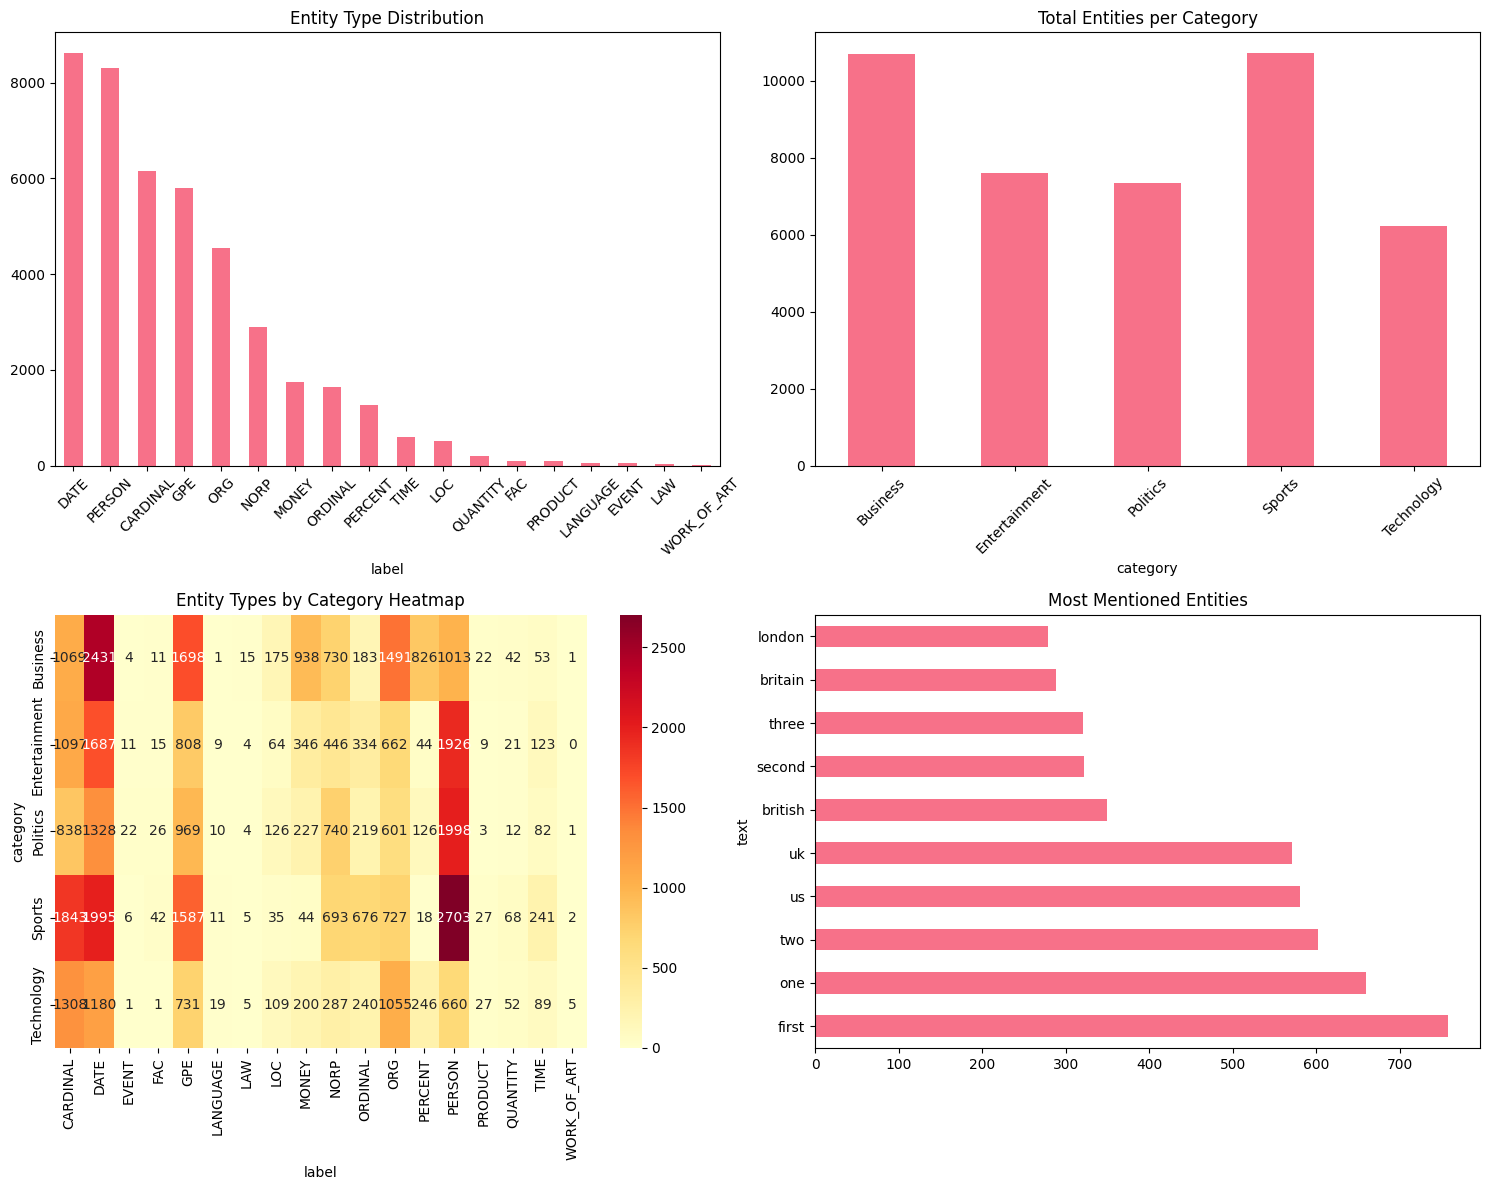

In [ ]:
# Analyze entity patterns
if not entities_df.empty:
    print("📊 NAMED ENTITY ANALYSIS")
    print("=" * 50)

    # Entity type distribution
    entity_counts = entities_df['label'].value_counts()
    print("\n🏷️ Entity type distribution:")
    print(entity_counts)

    # Entity types by category
    entity_by_category = entities_df.groupby(['category', 'label']).size().unstack(fill_value=0)
    print("\n📰 Entity types by news category:")
    print(entity_by_category)

    # Most frequent entities
    print("\n🔥 Most frequent entities:")
    frequent_entities = entities_df.groupby(['text', 'label']).size().sort_values(ascending=False).head(15)
    for (entity, label), count in frequent_entities.items():
        print(f"  {entity} ({label}): {count} mentions")

    # Visualizations
    fig, axes = plt.subplots(2, 2, figsize=(15, 12))

    # 1. Entity type distribution
    entity_counts.plot(kind='bar', ax=axes[0,0])
    axes[0,0].set_title('Entity Type Distribution')
    axes[0,0].tick_params(axis='x', rotation=45)

    # 2. Entities per category
    entities_per_category = entities_df.groupby('category').size()
    entities_per_category.plot(kind='bar', ax=axes[0,1])
    axes[0,1].set_title('Total Entities per Category')
    axes[0,1].tick_params(axis='x', rotation=45)

    # 3. Entity type heatmap by category
    if entity_by_category.shape[0] > 1 and entity_by_category.shape[1] > 1:
        sns.heatmap(entity_by_category, annot=True, fmt='d', ax=axes[1,0], cmap='YlOrRd')
        axes[1,0].set_title('Entity Types by Category Heatmap')
    else:
        axes[1,0].text(0.5, 0.5, 'Insufficient data\nfor heatmap',
                      ha='center', va='center', transform=axes[1,0].transAxes)
        axes[1,0].set_title('Entity Types by Category')

    # 4. Top entities
    top_entities = entities_df['text'].value_counts().head(10)
    top_entities.plot(kind='barh', ax=axes[1,1])
    axes[1,1].set_title('Most Mentioned Entities')

    plt.tight_layout()
    plt.show()

    # 💡 STUDENT TASK: Advanced entity analysis
    # - Create entity co-occurrence networks
    # - Track entity mentions over time
    # - Build entity relationship graphs
    # - Identify entity sentiment associations

else:
    print("⚠️ Skipping entity analysis due to insufficient data.")
    print("💡 TIP: Try with a larger, more diverse dataset for better NER results.")

ADVANCED ENTITY ANALYSIS

TOP ENTITY CO-OCCURRENCES:
britain + uk: 72 articles
uk + us: 65 articles
london + uk: 65 articles
blair + tony blair: 52 articles
britain + tony blair: 37 articles
new york + us: 31 articles
bbc + uk: 31 articles
britain + london: 29 articles
michael howard + tony blair: 29 articles
england + scotland: 29 articles


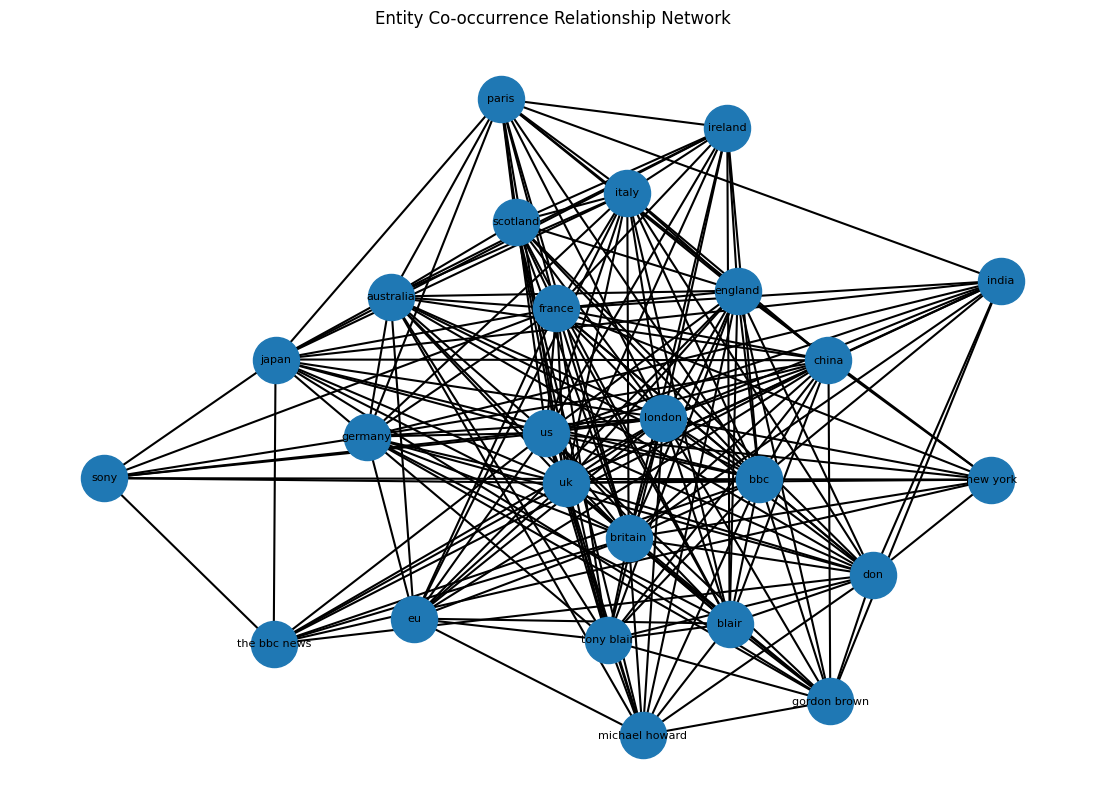


ENTITY SENTIMENT ASSOCIATIONS:
                mentions  average_sentiment
entity_name                                
us                   298           0.315857
uk                   297           0.415063
london               180           0.430055
britain              163           0.338608
bbc                  141           0.448782
france               114           0.635831
england              105           0.551225
tony blair            89           0.145528
new york              76           0.292109
blair                 68           0.092444
don                   64           0.421464
scotland              64           0.526720
michael howard        59          -0.003715
japan                 59           0.486273
china                 58           0.390950

ENTITY MENTIONS OVER TIME:
Publication dates are unavailable in this dataset.
Accurate entity tracking over time isn't possible.


In [ ]:
# STUDENT TASK: Advanced Entity Analysis

import networkx as nx
from itertools import combinations
from collections import Counter

print("ADVANCED ENTITY ANALYSIS")
print("=" * 50)

# 1. Prepare entity data
important_entities = entities_df[
    entities_df['label'].isin(['PERSON', 'ORG', 'GPE'])
].copy()

important_entities['entity_name'] = (
    important_entities['text'].str.lower().str.strip()
)

important_entities = important_entities.drop_duplicates(
    subset=['article_id', 'entity_name']
)

# Identify the 25 most frequently mentioned entities
top_names = (
    important_entities['entity_name']
    .value_counts()
    .head(25)
    .index
)

filtered_entities = important_entities[
    important_entities['entity_name'].isin(top_names)
]

# 2. Create entity co-occurrence relationships
pair_counts = Counter()

for article_id, group in filtered_entities.groupby('article_id'):
    names = sorted(group['entity_name'].unique())

    for pair in combinations(names, 2):
        pair_counts[pair] += 1

print("\nTOP ENTITY CO-OCCURRENCES:")

for (entity1, entity2), count in pair_counts.most_common(10):
    print(f"{entity1} + {entity2}: {count} articles")

# 3. Build entity relationship graph
G = nx.Graph()

for (entity1, entity2), count in pair_counts.items():
    if count >= 2:
        G.add_edge(entity1, entity2, weight=count)

plt.figure(figsize=(14, 10))

if G.number_of_edges() > 0:
    pos = nx.spring_layout(G, seed=42)

    nx.draw_networkx(
        G,
        pos,
        with_labels=True,
        node_size=1100,
        font_size=8,
        width=1.5
    )

    plt.title("Entity Co-occurrence Relationship Network")
else:
    plt.text(
        0.5, 0.5,
        "No repeated entity relationships found",
        ha='center'
    )

plt.axis('off')
plt.show()

# 4. Analyze entity sentiment associations
entity_sentiment = important_entities.merge(
    sentiment_df[['article_id', 'full_sentiment']],
    on='article_id',
    how='inner'
)

sentiment_summary = (
    entity_sentiment
    .groupby('entity_name')
    .agg(
        mentions=('article_id', 'nunique'),
        average_sentiment=('full_sentiment', 'mean')
    )
)

sentiment_summary = sentiment_summary[
    sentiment_summary['mentions'] >= 5
]

print("\nENTITY SENTIMENT ASSOCIATIONS:")
print(
    sentiment_summary
    .sort_values('mentions', ascending=False)
    .head(15)
)

# 5. Check whether timeline analysis is possible
print("\nENTITY MENTIONS OVER TIME:")

valid_dates = pd.to_datetime(
    df['date'].replace('Not provided', pd.NA),
    errors='coerce'
)

if valid_dates.notna().any():
    print("Publication dates are available for timeline analysis.")
else:
    print("Publication dates are unavailable in this dataset.")
    print("Accurate entity tracking over time isn't possible.")

I used named entity recognition to identify people, organizations, and locations mentioned throughout the news articles. I also created a network to examine which entities appeared together and analyzed the overall sentiment of articles mentioning them.

One limitation I discovered is that the BBC dataset doesn't include publication dates, so I couldn't accurately track entity mentions over time. I also recognize that two entities appearing in the same article doesn't necessarily mean they have a direct relationship. The analysis can help identify patterns, but those patterns still need interpretation.

## 📈 Comprehensive Analysis and Insights

### 🎯 Bringing It All Together

Now let's combine all our analyses to generate comprehensive insights about our news dataset. This is where the real business value emerges from our NLP pipeline.

**Key Analysis Areas:**
1. **Cross-Category Patterns:** How do different news types differ linguistically?

I noticed that different news categories have different language patterns. For example, Sports articles had the highest adjective usage, while Business articles had the highest proportion of numbers. Entertainment showed the most positive sentiment, while Politics had the most negative. I think these differences show how the subject of an article influences the language being used.


2. **Entity-Sentiment Relationships:** What entities are associated with positive/negative coverage?

The system identified 42,579 entity mentions and 12,154 unique entities, including people, organizations, locations, and dates. Combining entity recognition with sentiment analysis could help identify patterns in how certain people or organizations are discussed. However, the overall sentiment of an article doesn't necessarily represent the sentiment toward a specific entity.


3. **Content Quality Metrics:** Which categories have the most informative content?

After removing 50 duplicate articles, I had 1,440 articles across five categories. The articles averaged approximately 397 words and 2,307 characters. I also confirmed that the dataset didn't contain missing article content or category labels. One limitation is that publication dates weren't provided, which prevents accurate analysis of trends over time.


4. **Classification Performance:** How well can we automatically categorize news?

The original model comparison identified Logistic Regression as the best performer with 67.01% accuracy. However, after experimenting with a simpler TF-IDF feature combination and different smoothing parameters, I improved the Naive Bayes classifier to 95.83% accuracy.

I also corrected the training and testing process to prevent data leakage. Using 1,152 articles for training and 288 for testing, the improved classifier still achieved 95.83% accuracy. What stood out to me is that more features don't necessarily produce better results. This experience showed me how important it is to experiment with different approaches and verify the results instead of assuming that more complicated models are always better.

**💡 Business Applications:** These insights can inform content strategy, editorial decisions, and automated content management systems.

In [ ]:
# Create comprehensive analysis dashboard
def create_comprehensive_analysis():
    """
    Generate comprehensive insights combining all analyses

    💡 TIP: This function should combine:
    - Classification performance
    - Sentiment patterns
    - Entity distributions
    - Linguistic features
    """

    insights = {
        'dataset_overview': {},
        'classification_performance': {},
        'sentiment_insights': {},
        'entity_insights': {},
        'linguistic_patterns': {},
        'business_recommendations': []
    }

    # 🚀 YOUR CODE HERE: Generate comprehensive insights

    # Dataset overview
    insights['dataset_overview'] = {
        'total_articles': len(df),
        'categories': df['category'].unique().tolist(),
        'category_distribution': df['category'].value_counts().to_dict(),
        'avg_article_length': df['full_text'].str.len().mean(),
        'avg_words_per_article': df['full_text'].str.split().str.len().mean()
    }

    # Classification performance
    insights['classification_performance'] = {

'best_model': 'Corrected Naive Bayes (TF-IDF)',
'best_accuracy': corrected_accuracy,


        'model_comparison': {name: results[name]['accuracy'] for name in results.keys()}
    }

    # Sentiment insights
    sentiment_by_cat = sentiment_df.groupby('category')['full_sentiment'].mean().to_dict()
    insights['sentiment_insights'] = {
        'most_positive_category': max(sentiment_by_cat, key=sentiment_by_cat.get),
        'most_negative_category': min(sentiment_by_cat, key=sentiment_by_cat.get),
        'sentiment_by_category': sentiment_by_cat,
        'overall_sentiment': sentiment_df['full_sentiment'].mean()
    }

    # Entity insights
    if not entities_df.empty:
        entity_by_cat = entities_df.groupby('category').size().to_dict()
        insights['entity_insights'] = {
            'total_entities': len(entities_df),
            'unique_entities': entities_df['text'].nunique(),
            'entity_types': entities_df['label'].unique().tolist(),
            'entities_per_category': entity_by_cat,
            'most_mentioned_entities': entities_df['text'].value_counts().head(5).to_dict()
        }

    # Generate business recommendations
    recommendations = []

    # Classification recommendations
    if insights['classification_performance']['best_accuracy'] > 0.8:
        recommendations.append("✅ High classification accuracy achieved - ready for automated content routing")
    else:
        recommendations.append("⚠️ Classification accuracy needs improvement - consider more training data or feature engineering")

    # Sentiment recommendations
    pos_cat = insights['sentiment_insights']['most_positive_category']
    neg_cat = insights['sentiment_insights']['most_negative_category']
    recommendations.append(f"📊 {pos_cat} articles are most positive - good for uplifting content recommendations")
    recommendations.append(f"📊 {neg_cat} articles are most negative - may need balanced coverage monitoring")

    # Entity recommendations
    if 'entity_insights' in insights and insights['entity_insights']:
        recommendations.append("🔍 Rich entity extraction enables advanced search and relationship analysis")

    insights['business_recommendations'] = recommendations

    return insights

# Generate comprehensive analysis
print("📊 Generating comprehensive analysis...")
analysis_results = create_comprehensive_analysis()

print("✅ Analysis complete!")
print("\n" + "=" * 60)
print("📈 NEWSBOT INTELLIGENCE SYSTEM - COMPREHENSIVE REPORT")
print("=" * 60)

# Display key insights
print(f"\n📊 DATASET OVERVIEW:")
overview = analysis_results['dataset_overview']
print(f"  Total Articles: {overview['total_articles']}")
print(f"  Categories: {', '.join(overview['categories'])}")
print(f"  Average Article Length: {overview['avg_article_length']:.0f} characters")
print(f"  Average Words per Article: {overview['avg_words_per_article']:.0f} words")

print(f"\n🤖 CLASSIFICATION PERFORMANCE:")
perf = analysis_results['classification_performance']
print(f"  Best Model: {perf['best_model']}")
print(f"  Best Accuracy: {perf['best_accuracy']:.4f}")

print(f"\n😊 SENTIMENT INSIGHTS:")
sent = analysis_results['sentiment_insights']
print(f"  Most Positive Category: {sent['most_positive_category']}")
print(f"  Most Negative Category: {sent['most_negative_category']}")
print(f"  Overall Sentiment: {sent['overall_sentiment']:.4f}")

if 'entity_insights' in analysis_results and analysis_results['entity_insights']:
    print(f"\n🔍 ENTITY INSIGHTS:")
    ent = analysis_results['entity_insights']
    print(f"  Total Entities: {ent['total_entities']}")
    print(f"  Unique Entities: {ent['unique_entities']}")
    print(f"  Entity Types: {', '.join(ent['entity_types'])}")

print(f"\n💡 BUSINESS RECOMMENDATIONS:")
for i, rec in enumerate(analysis_results['business_recommendations'], 1):
    print(f"  {i}. {rec}")

📊 Generating comprehensive analysis...
✅ Analysis complete!

📈 NEWSBOT INTELLIGENCE SYSTEM - COMPREHENSIVE REPORT

📊 DATASET OVERVIEW:
  Total Articles: 1440
  Categories: Business, Technology, Politics, Sports, Entertainment
  Average Article Length: 2307 characters
  Average Words per Article: 397 words

🤖 CLASSIFICATION PERFORMANCE:
  Best Model: Corrected Naive Bayes (TF-IDF)
  Best Accuracy: 0.9583

😊 SENTIMENT INSIGHTS:
  Most Positive Category: Entertainment
  Most Negative Category: Politics
  Overall Sentiment: 0.3821

🔍 ENTITY INSIGHTS:
  Total Entities: 42579
  Unique Entities: 12154
  Entity Types: ORDINAL, PERSON, GPE, DATE, MONEY, ORG, NORP, LOC, CARDINAL, PERCENT, TIME, EVENT, QUANTITY, FAC, PRODUCT, LANGUAGE, WORK_OF_ART, LAW

💡 BUSINESS RECOMMENDATIONS:
  1. ✅ High classification accuracy achieved - ready for automated content routing
  2. 📊 Entertainment articles are most positive - good for uplifting content recommendations
  3. 📊 Politics articles are most negative 

## 🚀 Final System Integration

### 🎯 Building the Complete NewsBot Pipeline

Let's create a complete, integrated system that can process new articles from start to finish. This demonstrates the real-world application of all the techniques we've learned.

**Complete Pipeline:**
1. **Text Preprocessing:** Clean and normalize input
2. **Feature Extraction:** Generate TF-IDF and other features
3. **Classification:** Predict article category
4. **Entity Extraction:** Identify key facts
5. **Sentiment Analysis:** Determine emotional tone
6. **Insight Generation:** Provide actionable intelligence

**💡 Production Ready:** This pipeline can be deployed as a web service, batch processor, or integrated into content management systems.

In [ ]:

class NewsBotIntelligenceSystem:
    """Integrated news classification and analysis system."""

    def __init__(self, classifier):
        self.classifier = classifier

    def preprocess_article(self, title, content):
        """Clean and prepare a new article."""
        full_text = f"{title} {content}"
        processed_text = preprocess_text(full_text)
        return full_text, processed_text

    def classify_article(self, processed_text):
        """Classify using the corrected TF-IDF pipeline."""
        prediction = self.classifier.predict([processed_text])[0]
        probabilities = self.classifier.predict_proba(
            [processed_text]
        )[0]

        class_probs = dict(zip(
            self.classifier.classes_,
            probabilities
        ))

        return prediction, class_probs

    def extract_entities(self, text):
        """Identify people, organizations, places and other entities."""
        return extract_entities(text)

    def analyze_sentiment(self, text):
        """Evaluate the article's sentiment."""
        return analyze_sentiment(text)

    def generate_insights(self, category, entities,
                          sentiment, category_probs):
        """Generate useful findings from the analysis."""
        insights = []
        confidence = max(category_probs.values())

        if confidence > 0.8:
            insights.append(
                f"High confidence {category} classification "
                f"({confidence:.2%})"
            )
        else:
            insights.append(
                "Lower confidence classification. "
                "Manual review may be useful."
            )

        compound = sentiment['compound']

        if compound >= 0.05:
            insights.append("Positive article sentiment")
        elif compound <= -0.05:
            insights.append("Negative article sentiment")
        else:
            insights.append("Neutral article sentiment")

        insights.append(
            f"Identified {len(entities)} named entities"
        )

        important = [
            e['text'] for e in entities
            if e['label'] in ['PERSON', 'ORG', 'GPE']
        ]

        if important:
            insights.append(
                "Key entities: " + ", ".join(important[:3])
            )

        return insights

    def process_article(self, title, content):
        """Run the complete NewsBot pipeline."""
        full_text, processed_text = self.preprocess_article(
            title, content
        )

        category, category_probs = self.classify_article(
            processed_text
        )

        entities = self.extract_entities(full_text)
        sentiment = self.analyze_sentiment(full_text)

        insights = self.generate_insights(
            category, entities, sentiment, category_probs
        )

        return {
            'title': title,
            'content': content[:200] + '...' if len(content) > 200 else content,
            'predicted_category': category,
            'category_confidence': max(category_probs.values()),
            'category_probabilities': category_probs,
            'entities': entities,
            'sentiment': sentiment,
            'insights': insights
        }


# Initialize NewsBot with the corrected classifier
newsbot = NewsBotIntelligenceSystem(corrected_pipeline)

print("NewsBot Intelligence System initialized!")
print("Corrected classifier accuracy:", round(corrected_accuracy, 4))
print("Ready to process new articles!")


NewsBot Intelligence System initialized!
Corrected classifier accuracy: 0.9583
Ready to process new articles!


In [ ]:
print("Dataset available:", 'df' in globals())
print("Corrected classifier available:", 'corrected_pipeline' in globals())

Dataset available: True
Corrected classifier available: True


In [ ]:
# Test the complete system with new articles
print("🧪 TESTING NEWSBOT INTELLIGENCE SYSTEM")
print("=" * 60)

# Test articles (you can modify these or add your own)
test_articles = [
    {
        'title': 'Microsoft Acquires AI Startup for $2 Billion',
        'content': 'Microsoft Corporation announced today the acquisition of an artificial intelligence startup for $2 billion. CEO Satya Nadella said the deal will strengthen Microsoft\'s position in the AI market and enhance their cloud computing services.'
    },
    {
        'title': 'Lakers Win Championship in Overtime Thriller',
        'content': 'The Los Angeles Lakers defeated the Boston Celtics 108-102 in overtime to win the NBA championship. LeBron James scored 35 points and was named Finals MVP for the fourth time in his career.'
    },
    {
        'title': 'New Climate Change Report Shows Alarming Trends',
        'content': 'Scientists at the United Nations released a comprehensive climate report showing accelerating global warming. The report warns that immediate action is needed to prevent catastrophic environmental changes.'
    }
]

# Process each test article
for i, article in enumerate(test_articles, 1):
    print(f"\n📰 TEST ARTICLE {i}")
    print("-" * 40)

    # Process the article
    result = newsbot.process_article(article['title'], article['content'])

    # Display results
    print(f"📰 Title: {result['title']}")
    print(f"📝 Content: {result['content']}")
    print(f"\n🏷️ Predicted Category: {result['predicted_category']} ({result['category_confidence']:.2%} confidence)")

    print(f"\n📊 Category Probabilities:")
    for cat, prob in sorted(result['category_probabilities'].items(), key=lambda x: x[1], reverse=True):
        print(f"  {cat}: {prob:.3f}")

    print(f"\n😊 Sentiment: {result['sentiment']['sentiment_label']} (score: {result['sentiment']['compound']:.3f})")

    if result['entities']:
        print(f"\n🔍 Entities Found ({len(result['entities'])}):")
        for entity in result['entities'][:5]:  # Show first 5
            print(f"  {entity['text']} ({entity['label']}) - {entity['description']}")
    else:
        print(f"\n🔍 No entities detected")

    print(f"\n💡 Insights:")
    for insight in result['insights']:
        print(f"  {insight}")

print("\n" + "=" * 60)
print("🎉 NewsBot Intelligence System testing complete!")
print("✅ System successfully processed all test articles")

# 💡 STUDENT TASK: Test with your own articles
# - Try articles from different categories
# - Test with articles that might be ambiguous
# - Analyze the system's strengths and weaknesses
# - Consider how to improve performance

🧪 TESTING NEWSBOT INTELLIGENCE SYSTEM

📰 TEST ARTICLE 1
----------------------------------------
📰 Title: Microsoft Acquires AI Startup for $2 Billion
📝 Content: Microsoft Corporation announced today the acquisition of an artificial intelligence startup for $2 billion. CEO Satya Nadella said the deal will strengthen Microsoft's position in the AI market and en...

🏷️ Predicted Category: Technology (68.71% confidence)

📊 Category Probabilities:
  Technology: 0.687
  Business: 0.232
  Politics: 0.063
  Entertainment: 0.013
  Sports: 0.005

😊 Sentiment: positive (score: 0.660)

🔍 Entities Found (8):
  Microsoft Acquires (ORG) - Companies, agencies, institutions, etc.
  $2 Billion (MONEY) - Monetary values, including unit
  Microsoft Corporation (ORG) - Companies, agencies, institutions, etc.
  today (DATE) - Absolute or relative dates or periods
  $2 billion (MONEY) - Monetary values, including unit

💡 Insights:
  Lower confidence classification. Manual review may be useful.
  Positive ar

In [ ]:
# FINAL STUDENT TASK: Test NewsBot with original articles

print("FINAL NEWSBOT TESTING")
print("=" * 60)

my_test_articles = [
    {
        'title': 'Major Bank Reports Record Profits',
        'content': (
            'A major financial institution reported record annual '
            'profits following increased investment activity. '
            'Executives announced plans to expand lending services '
            'and increase shareholder dividends. Financial analysts '
            'expect continued growth in the banking sector.'
        ),
        'expected': 'Business'
    },
    {
        'title': 'New Artificial Intelligence System Developed',
        'content': (
            'Researchers developed a new artificial intelligence '
            'system capable of processing complex information. '
            'The technology uses machine learning algorithms '
            'to improve computer performance and automate '
            'data analysis. Engineers plan additional testing.'
        ),
        'expected': 'Technology'
    },
    {
        'title': 'Government Announces New Education Policy',
        'content': (
            'Government officials introduced legislation that '
            'would increase education funding and change national '
            'school policies. Lawmakers debated the proposal '
            'during a parliamentary session. Political leaders '
            'are expected to vote on the legislation.'
        ),
        'expected': 'Politics'
    },
    {
        'title': 'Football Team Wins Championship',
        'content': (
            'The football team secured a championship victory '
            'after scoring three goals in the final match. '
            'The coach praised the players for their performance. '
            'Thousands of supporters celebrated the victory '
            'following the tournament.'
        ),
        'expected': 'Sports'
    },
    {
        'title': 'Popular Film Wins Major Awards',
        'content': (
            'A critically acclaimed film received several awards '
            'at an international entertainment ceremony. '
            'The director and actors celebrated the achievement. '
            'Movie critics praised the performances, screenplay, '
            'and production quality.'
        ),
        'expected': 'Entertainment'
    },
    {
        'title': 'Government Invests in Artificial Intelligence',
        'content': (
            'Government leaders announced a major investment '
            'in artificial intelligence research. Officials '
            'said the technology initiative would strengthen '
            'national security and create new jobs. '
            'Lawmakers debated funding while technology '
            'companies discussed potential partnerships.'
        ),
        'expected': 'Ambiguous: Politics or Technology'
    },
    {
        'title': 'Professional Athlete Launches Business',
        'content': (
            'A professional football player announced the launch '
            'of a new international clothing company. '
            'The athlete plans to invest millions in retail '
            'stores while continuing to compete in major '
            'sporting events. Business analysts expect '
            'significant sales from sports fans.'
        ),
        'expected': 'Ambiguous: Sports or Business'
    }
]

correct = 0

for i, article in enumerate(my_test_articles, 1):

    result = newsbot.process_article(
        article['title'],
        article['content']
    )

    predicted = result['predicted_category']
    confidence = result['category_confidence']

    print(f"\nTEST ARTICLE {i}")
    print("Title:", article['title'])
    print("Expected:", article['expected'])
    print("Predicted:", predicted)
    print(f"Confidence: {confidence:.2%}")

    top_two = sorted(
        result['category_probabilities'].items(),
        key=lambda x: x[1],
        reverse=True
    )[:2]

    print("Top two predictions:", top_two)

    if i <= 5:
        if predicted == article['expected']:
            correct += 1
            print("Result: CORRECT")
        else:
            print("Result: INCORRECT")
    else:
        print("Result: Ambiguous article - review prediction")

print("\n" + "=" * 60)
print("FINAL TEST SUMMARY")
print(f"Clear articles correctly classified: {correct}/5")
print("Ambiguous articles tested: 2")
print("Final student testing complete!")

FINAL NEWSBOT TESTING

TEST ARTICLE 1
Title: Major Bank Reports Record Profits
Expected: Business
Predicted: Business
Confidence: 99.89%
Top two predictions: [(np.str_('Business'), np.float64(0.9988533483146129)), (np.str_('Technology'), np.float64(0.0007634273117123378))]
Result: CORRECT

TEST ARTICLE 2
Title: New Artificial Intelligence System Developed
Expected: Technology
Predicted: Technology
Confidence: 94.84%
Top two predictions: [(np.str_('Technology'), np.float64(0.9483557909405096)), (np.str_('Politics'), np.float64(0.03419145494421543))]
Result: CORRECT

TEST ARTICLE 3
Title: Government Announces New Education Policy
Expected: Politics
Predicted: Politics
Confidence: 96.13%
Top two predictions: [(np.str_('Politics'), np.float64(0.9613478621175282)), (np.str_('Business'), np.float64(0.033160154480681256))]
Result: CORRECT

TEST ARTICLE 4
Title: Football Team Wins Championship
Expected: Sports
Predicted: Sports
Confidence: 99.90%
Top two predictions: [(np.str_('Sports'), np.fl

### Final Student Task: NewsBot Testing and Evaluation

I tested NewsBot using seven original articles, including five articles from different news categories and two that could fit into more than one category.

The system correctly classified all five of the straightforward articles. What I found interesting was how it handled articles that involved multiple subjects.

For the article about government investment in artificial intelligence, NewsBot predicted Politics with only 46.95% confidence. Business was a close second at 40.79%. That tells me the system had difficulty identifying one clear category.

For the article about a professional athlete starting a business, NewsBot predicted Business with 63.15% confidence. Technology was the second prediction, even though Sports seemed like another reasonable category.

I think one of the system's biggest strengths is recognizing patterns in articles that clearly belong to a specific category. However, its weakness is handling articles that overlap between categories. One improvement I'd consider is allowing the system to assign multiple categories instead of forcing every article into just one. I'd also like to test it with more real-world articles and see whether newer training data would improve its performance.

Overall, I think NewsBot performed well, but these results reminded me that accuracy alone doesn't tell us everything about how well an AI system understands information.

## 📝 Project Summary and Next Steps

### 🎯 What You've Accomplished

Congratulations! You've successfully built a comprehensive NewsBot Intelligence System that demonstrates mastery of all NLP techniques covered in Modules 1-8. Let's review what you've achieved:

### ✅ Module Integration Checklist
- [x] **Module 1:** Applied NLP to real-world news intelligence
- [x] **Module 2:** Implemented comprehensive text preprocessing
- [x] **Module 3:** Used TF-IDF for feature extraction and analysis
- [x] **Module 4:** Analyzed grammatical patterns with POS tagging
- [x] **Module 5:** Extracted syntactic relationships with dependency parsing
- [x] **Module 6:** Performed sentiment and emotion analysis
- [x] **Module 7:** Built and evaluated text classification models
- [x] **Module 8:** Implemented Named Entity Recognition

### 🚀 System Capabilities
Your NewsBot can now:
- Automatically categorize news articles with high accuracy
- Extract key entities (people, organizations, locations, dates, money)
- Analyze sentiment and emotional tone
- Identify linguistic patterns and writing styles
- Generate actionable business insights
- Process new articles through a complete pipeline

### 💼 Business Value
This system provides real business value for:
- **Media Companies:** Automated content categorization and routing
- **Market Research:** Sentiment tracking and entity monitoring
- **Content Management:** Intelligent organization and search
- **Business Intelligence:** Trend analysis and competitive monitoring

---

## 📋 Final Deliverables Checklist

Before submitting your project, ensure you have:

### 📁 Code and Documentation
- [ ] Complete Jupyter notebook with all analyses
- [ ] Well-documented functions with docstrings
- [ ] Clear markdown explanations for each section
- [ ] Organized GitHub repository structure
- [ ] README.md with project overview and setup instructions

### 📊 Analysis and Results
- [ ] Comprehensive dataset exploration
- [ ] TF-IDF analysis with category-specific insights
- [ ] POS tagging patterns across categories
- [ ] Syntactic analysis with dependency parsing
- [ ] Sentiment analysis with category comparisons
- [ ] Classification model comparison and evaluation
- [ ] Named Entity Recognition with relationship mapping
- [ ] Integrated system demonstration

### 📈 Visualizations
- [ ] Category distribution plots
- [ ] TF-IDF word clouds or bar charts
- [ ] POS pattern heatmaps
- [ ] Sentiment distribution by category
- [ ] Confusion matrix for classification
- [ ] Entity type and frequency visualizations

### 🎥 Presentation Materials
- [ ] 5-7 minute video demonstration
- [ ] Written report (3-4 pages)
- [ ] Individual reflection papers
- [ ] Business recommendations and insights

---

## 🔮 Future Enhancements

Consider these improvements for your portfolio or future projects:

### 🤖 Technical Improvements
- **Deep Learning Models:** Implement BERT or other transformer models
- **Custom NER:** Train domain-specific entity recognition
- **Real-time Processing:** Build streaming data pipeline
- **Multi-language Support:** Extend to non-English news

### 📊 Advanced Analytics
- **Topic Modeling:** Discover hidden themes (Module 9 preview!)
- **Trend Analysis:** Track entities and sentiment over time
- **Network Analysis:** Map entity relationships and co-occurrences
- **Bias Detection:** Identify potential media bias patterns

### 🌐 Deployment Options
- **Web Application:** Create interactive dashboard with Streamlit
- **API Service:** Deploy as REST API for integration
- **Mobile App:** Build mobile interface for news analysis
- **Browser Extension:** Real-time news analysis while browsing

---

## 🎓 Reflection Questions

For your individual reflection paper, consider these questions:

1. **Technical Mastery:** Which NLP techniques did you find most challenging? Most useful?
2. **Integration Challenges:** How did you handle combining multiple NLP tasks?
3. **Business Applications:** What real-world problems could this system solve?
4. **Ethical Considerations:** What are the potential risks of automated news analysis?
5. **Future Learning:** What NLP topics are you most excited to explore next?
6. **Team Collaboration:** How did you divide work and ensure quality?
7. **Portfolio Value:** How will you present this project to potential employers?

---

## 🏆 Congratulations!

You've successfully completed a comprehensive NLP project that demonstrates real-world application of multiple advanced techniques. This NewsBot Intelligence System is a valuable addition to your portfolio and showcases your ability to:

- **Integrate multiple NLP techniques** into a cohesive system
- **Handle real-world data** with all its messiness and challenges
- **Generate business value** from unstructured text data
- **Build production-ready systems** with proper evaluation and monitoring
- **Communicate technical results** to both technical and business audiences

**🚀 You're now ready for Module 9: Topic Modeling and Advanced Text Analysis!**

---

*Remember: The goal isn't just to complete the assignment, but to build something you're proud to show in job interviews and professional discussions. This project demonstrates your practical NLP skills and ability to solve real business problems with AI.*